Loading of data and initial exploration of the data. 
CONTENTS OF THIS NOTEBOOK
1. [Loading of data](#1)
2. [Initial exploration of the data](#2)
3. [Data cleaning](#3)
4. [Feature engineering](#4)
5. [Data visualization](#5)
6. [Data preparation for modelling](#6)
7. [Modelling](#7)
8. [Submission](#8)

<a id="1"></a> <br>
## 1. Loading of data


In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import os
import json
import folium
from folium.plugins import MarkerCluster
from folium.plugins import FastMarkerCluster
from folium.plugins import HeatMap
import geoplot
import pysal
from pysal.lib import weights
import mapclassify as mc
import rioxarray as rxr
import contextily as ctx



In [5]:
# Read in the polygon shapefile of baronies.

baronies = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Baronies_-_OSi_National_Statutory_Boundaries_Generalised')
# baronies = baronies.to_crs(epsg=4326)
baronies.info()
baronies.head()



<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   BY_ID       280 non-null    object  
 1   ENGLISH     280 non-null    object  
 2   GAEILGE     278 non-null    object  
 3   LOGAINM_ID  279 non-null    object  
 4   CONTAE      280 non-null    object  
 5   COUNTY      280 non-null    object  
 6   PROVINCE    280 non-null    object  
 7   GUID        280 non-null    object  
 8   CENTROID_X  280 non-null    float64 
 9   CENTROID_Y  280 non-null    float64 
 10  AREA        280 non-null    float64 
 11  OBJECTID    280 non-null    int64   
 12  Shape__Are  280 non-null    float64 
 13  Shape__Len  280 non-null    float64 
 14  geometry    280 non-null    geometry
dtypes: float64(5), geometry(1), int64(1), object(8)
memory usage: 32.9+ KB


,BY_ID,ENGLISH,GAEILGE,LOGAINM_ID,CONTAE,COUNTY,PROVINCE,GUID,CENTROID_X,CENTROID_Y,AREA,OBJECTID,Shape__Are,Shape__Len,geometry
0,39010,TULLA LOWER,An Tulach Íochtarach,26,An Clár,CLARE,Munster,2ae19629-11cb-13a3-e055-000000000001,560469.00,671232.75,3.168842e+08,1,3.168702e+08,110513.797351,"POLYGON ((563295.879 659871.427, 563338.373 65..."
1,49008,CARBERY WEST (West Division),Cairbrigh Thiar (an Roinn Thiar),37,Corcaigh,CORK,Munster,2ae19629-11d5-13a3-e055-000000000001,492527.15,536425.72,4.448645e+08,2,4.446265e+08,389992.653563,"MULTIPOLYGON (((503268.762 534341.449, 503362...."
2,219014,GLENAHIRY,Gleann na hUidhre,245,Tiobraid Árann,TIPPERARY,Munster,2ae19629-1188-13a3-e055-000000000001,620810.23,622147.46,1.208773e+06,3,1.201650e+06,7805.611474,"POLYGON ((622234.178 622796.243, 622326.173 62..."
3,179005,TROUGH,An Triúcha,202,Muineachán,MONAGHAN,Ulster,2ae19629-1101-13a3-e055-000000000001,665124.94,844117.19,1.513749e+08,4,1.513421e+08,81230.745640,"POLYGON ((657648.441 842970.492, 656713.943 84..."
4,79003,DUNKERRON NORTH,Dún Ciaráin Thuaidh,90,Ciarraí,KERRY,Munster,2ae19629-1170-13a3-e055-000000000001,480733.37,585023.49,2.994577e+08,5,2.994500e+08,93710.738684,"POLYGON ((491581.400 590195.836, 493206.007 58..."


In [19]:
baronies.columns


Index(['BY_ID', 'ENGLISH', 'GAEILGE', 'LOGAINM_ID', 'CONTAE', 'COUNTY',
       'PROVINCE', 'GUID', 'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID',
       'Shape__Are', 'Shape__Len', 'geometry'],
      dtype='object')

In [21]:
# Output LATEX table of the head of this geodataframe for report, drop multiple columns as they wont fit on the page 

columns_to_drop = ['geometry', 'PROVINCE', 'LOGAINM_ID', 'CONTAE', 'GUID', 'Shape__Are', 'Shape__Len'] 

baronies_short = baronies.drop(columns = columns_to_drop).head()

latex_table = baronies_short.to_latex(index=False, escape=False)

print(latex_table)


\begin{tabular}{llllrrrr}
\toprule
BY_ID & ENGLISH & GAEILGE & COUNTY & CENTROID_X & CENTROID_Y & AREA & OBJECTID \\
\midrule
39010 & TULLA LOWER & An Tulach Íochtarach & CLARE & 560469.000000 & 671232.750000 & 316884151.280000 & 1 \\
49008 & CARBERY WEST (West Division) & Cairbrigh Thiar (an Roinn Thiar) & CORK & 492527.150000 & 536425.720000 & 444864512.060000 & 2 \\
219014 & GLENAHIRY & Gleann na hUidhre & TIPPERARY & 620810.230000 & 622147.460000 & 1208773.350000 & 3 \\
179005 & TROUGH & An Triúcha & MONAGHAN & 665124.940000 & 844117.190000 & 151374904.760000 & 4 \\
79003 & DUNKERRON NORTH & Dún Ciaráin Thuaidh & KERRY & 480733.370000 & 585023.490000 & 299457692.670000 & 5 \\
\bottomrule
\end{tabular}



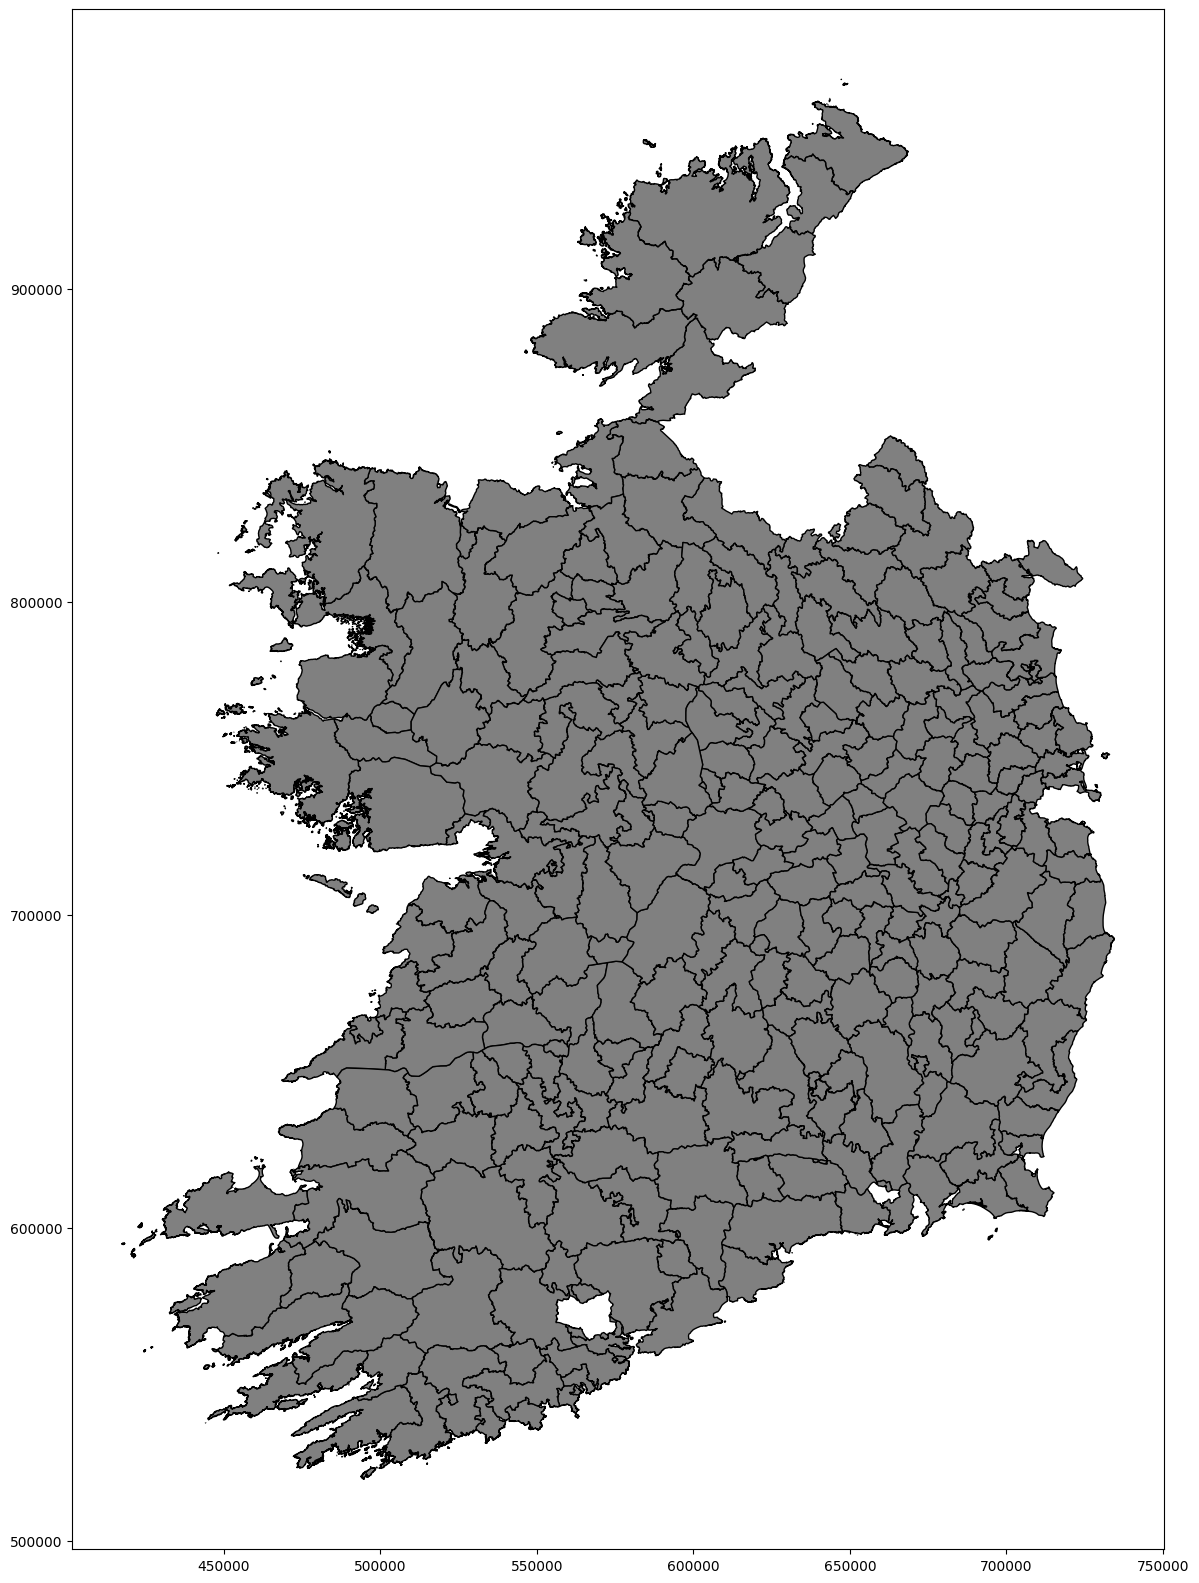

In [3]:
# Plot the baronies

ax, fig = plt.subplots(figsize=(20,20))
baronies.plot(ax=fig, color='gray', edgecolor='black')
plt.show()

In [4]:
# Check the CRS of the baronies. This is the Coordinate Reference System and is important for accurate mapping.
# The CRS is the Irish Transverse Mercator (ITM) system. This is a projected coordinate system that is used in Ireland.
# The EPSG code for this is 2157. A projected coordinate system is more accurate for angles and distances than a 
# geographic coordinate system.

baronies.crs


<Projected CRS: EPSG:2157>
Name: IRENET95 / Irish Transverse Mercator
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Ireland - onshore. United Kingdom (UK) - Northern Ireland (Ulster) - onshore.
- bounds: (-10.56, 51.39, -5.34, 55.43)
Coordinate Operation:
- name: Irish Transverse Mercator
- method: Transverse Mercator
Datum: IRENET95
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [5]:
# create copy of baronies

baronies_copy = baronies.copy()

# selest all baronies where county is donegal sligo and leitrim
baronies_copy = baronies_copy[baronies_copy['COUNTY'].isin(['DONEGAL', 'SLIGO', 'LEITRIM'])]
baronies_copy.info()
baronies_copy.head()



<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 19 entries, 12 to 279
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   BY_ID       19 non-null     object  
 1   ENGLISH     19 non-null     object  
 2   GAEILGE     19 non-null     object  
 3   LOGAINM_ID  19 non-null     object  
 4   CONTAE      19 non-null     object  
 5   COUNTY      19 non-null     object  
 6   PROVINCE    19 non-null     object  
 7   GUID        19 non-null     object  
 8   CENTROID_X  19 non-null     float64 
 9   CENTROID_Y  19 non-null     float64 
 10  AREA        19 non-null     float64 
 11  OBJECTID    19 non-null     int64   
 12  Shape__Are  19 non-null     float64 
 13  Shape__Len  19 non-null     float64 
 14  geometry    19 non-null     geometry
dtypes: float64(5), geometry(1), int64(1), object(8)
memory usage: 2.4+ KB


,BY_ID,ENGLISH,GAEILGE,LOGAINM_ID,CONTAE,COUNTY,PROVINCE,GUID,CENTROID_X,CENTROID_Y,AREA,OBJECTID,Shape__Are,Shape__Len,geometry
12,59008,TIRHUGH,Tír Aodha,52,Dún na nGall,DONEGAL,Ulster,2ae19629-11ec-13a3-e055-000000000001,599471.23,873654.18,5.197514e+08,13,5.197586e+08,200162.686389,"MULTIPOLYGON (((595713.002 881098.568, 596161...."
42,119002,DRUMAHAIRE,Droim Dhá Thiar,137,Liatroim,LEITRIM,Connacht,2ae19629-111a-13a3-e055-000000000001,592206.80,829758.65,4.740572e+08,43,4.740812e+08,143658.292704,"POLYGON ((597990.378 818769.081, 596669.263 81..."
94,59005,KILMACRENAN,Cill Mhic Réanáin,55,Dún na nGall,DONEGAL,Ulster,2ae19629-11e9-13a3-e055-000000000001,603124.29,925861.29,1.262017e+09,95,1.261950e+09,565575.016132,"MULTIPOLYGON (((594771.077 934748.331, 594787...."
129,209003,CORRAN,An Corann,229,Sligeach,SLIGO,Connacht,2ae19629-115b-13a3-e055-000000000001,566808.50,814338.53,1.846223e+08,130,1.845969e+08,85627.186286,"POLYGON ((571532.180 816627.484, 571534.486 81..."
141,59001,BANAGH,Báinigh,54,Dún na nGall,DONEGAL,Ulster,2ae19629-11e5-13a3-e055-000000000001,573655.32,881367.13,7.226286e+08,142,7.226265e+08,305215.235318,"MULTIPOLYGON (((596157.164 893589.045, 596226...."


In [6]:
# print out all the column entries by_id, English column names of the territories

baronies_copy['BY_ID']
baronies_copy['ENGLISH']




12            TIRHUGH
42         DRUMAHAIRE
94        KILMACRENAN
129            CORRAN
141            BANAGH
142          COOLAVIN
144           LEITRIM
161          TIRERAGH
173    INISHOWEN EAST
175        ROSCLOGHER
199      RAPHOE SOUTH
204    INISHOWEN WEST
237             LEYNY
238           CARBURY
240         TIRERRILL
255            MOHILL
274           BOYLAGH
277      RAPHOE NORTH
279       CARRIGALLEN
Name: ENGLISH, dtype: object

In [7]:
# dir returns all the attributes and methods of an object. This is useful for finding out what you can do with an 
# object. These are the attributes and methods of the baronies_copy object. A GeoDataFrame object.

dir(baronies_copy)

['AREA',
 'BY_ID',
 'CENTROID_X',
 'CENTROID_Y',
 'CONTAE',
 'COUNTY',
 'ENGLISH',
 'GAEILGE',
 'GUID',
 'LOGAINM_ID',
 'OBJECTID',
 'PROVINCE',
 'Shape__Are',
 'Shape__Len',
 'T',
 '_AXIS_LEN',
 '_AXIS_ORDERS',
 '_AXIS_TO_AXIS_NUMBER',
 '_HANDLED_TYPES',
 '__abs__',
 '__add__',
 '__and__',
 '__annotations__',
 '__array__',
 '__array_priority__',
 '__array_ufunc__',
 '__bool__',
 '__class__',
 '__contains__',
 '__copy__',
 '__dataframe__',
 '__dataframe_consortium_standard__',
 '__deepcopy__',
 '__delattr__',
 '__delitem__',
 '__dict__',
 '__dir__',
 '__divmod__',
 '__doc__',
 '__eq__',
 '__finalize__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__geo_interface__',
 '__getattr__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__iadd__',
 '__iand__',
 '__ifloordiv__',
 '__imod__',
 '__imul__',
 '__init__',
 '__init_subclass__',
 '__invert__',
 '__ior__',
 '__ipow__',
 '__isub__',
 '__iter__',
 '__itruediv__',
 '__ixor__',
 '__le__',
 '__len__',
 '__lt

In [8]:
# read in the shapefile file of the baronies and territories, this is an alternative source of the baronies data
# from Open Map, this contains the whole island.

baronies2 = gpd.read_file('/Users/mensab/Documents/GISMapFiles/baronies')
# baronies2 = baronies2.to_crs(epsg=4326)
baronies2.head()
baronies2.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 328 entries, 0 to 327
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OSM_ID      328 non-null    float64 
 1   NAME_TAG    328 non-null    object  
 2   NAME_GA     325 non-null    object  
 3   NAME_EN     323 non-null    object  
 4   ALT_NAME    8 non-null      object  
 5   LOGAINM_RE  325 non-null    object  
 6   ALT_NAME_G  2 non-null      object  
 7   OSM_USER    327 non-null    object  
 8   OSM_TIMEST  327 non-null    object  
 9   ATTRIBUTIO  0 non-null      float64 
 10  CO_NAME     310 non-null    object  
 11  CO_OSM_ID   310 non-null    float64 
 12  T_IE_URL    328 non-null    object  
 13  AREA        328 non-null    float64 
 14  LATITUDE    328 non-null    float64 
 15  LONGITUDE   328 non-null    float64 
 16  EPOCH_TSTM  327 non-null    float64 
 17  geometry    328 non-null    geometry
dtypes: float64(7), geometry(1), object(10)
mem

In [9]:
dir

<function dir>

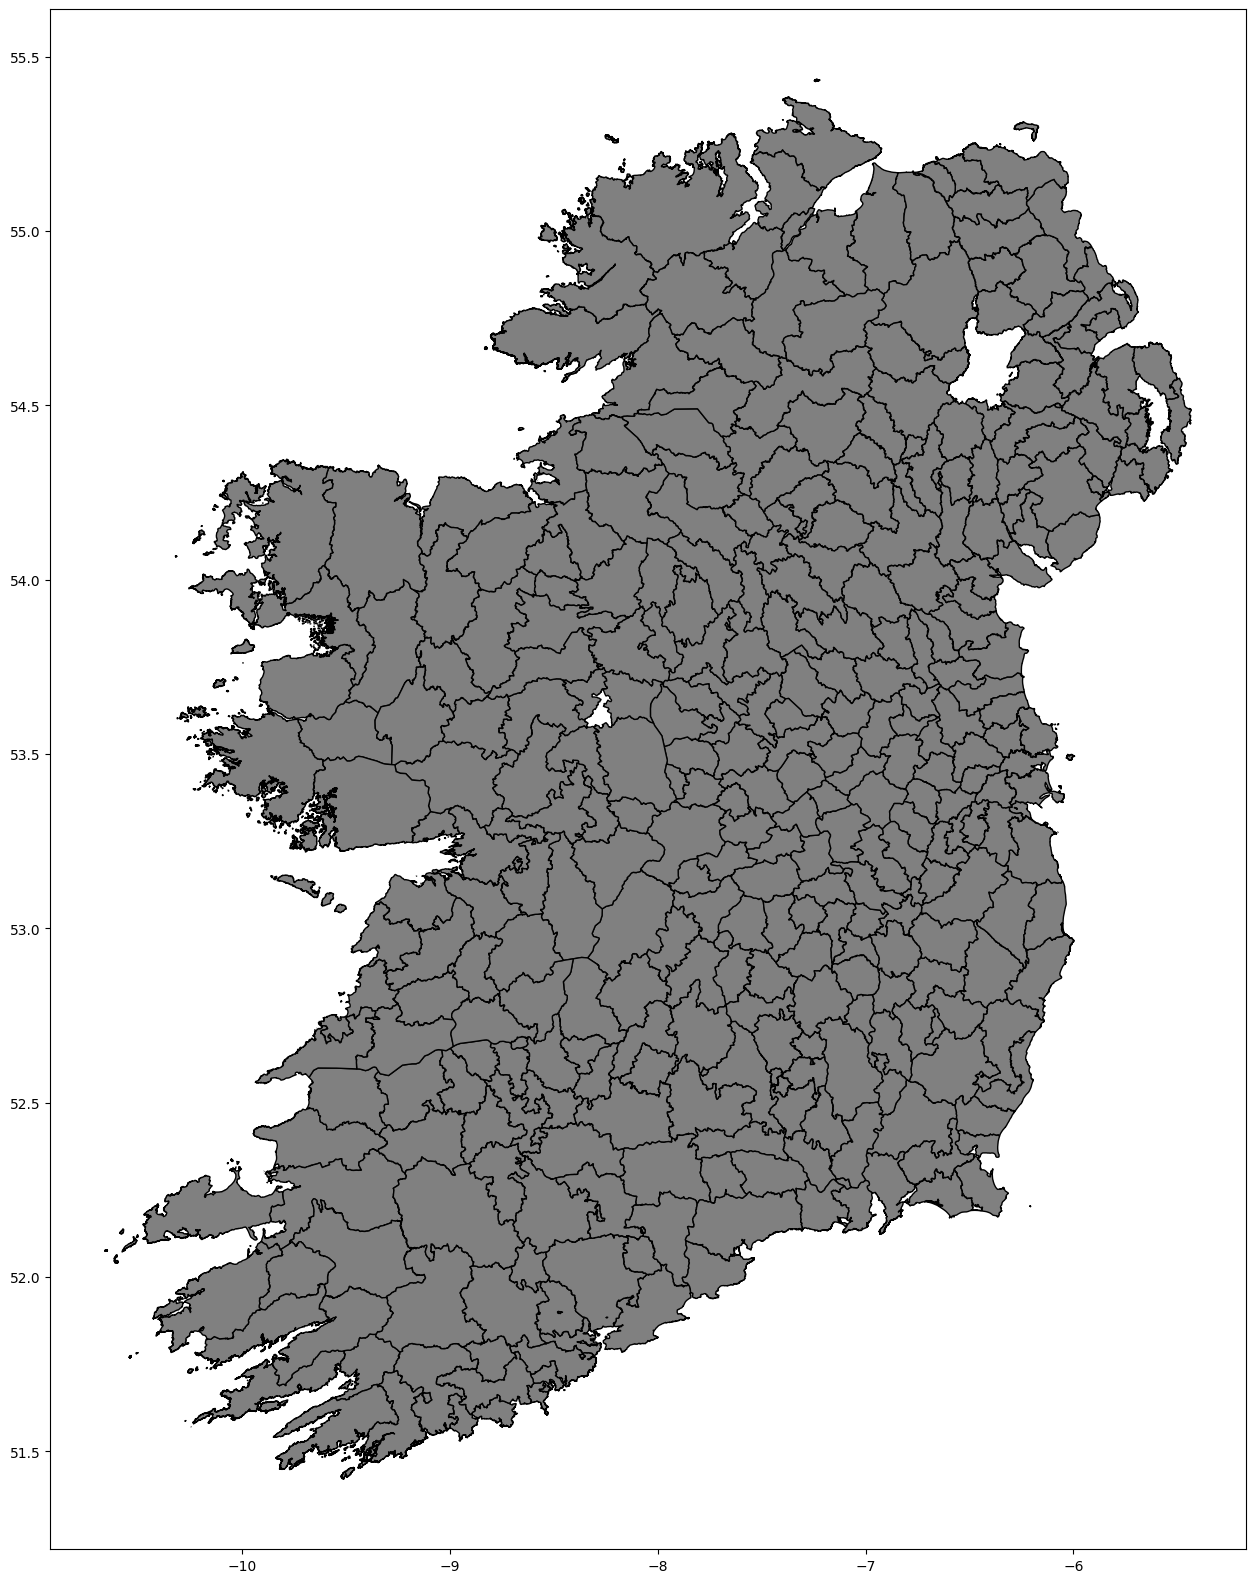

In [10]:
# Plot the baronies

ax, fig = plt.subplots(figsize=(20,20))
baronies2.plot(ax=fig, color='gray', edgecolor='black')
plt.show()


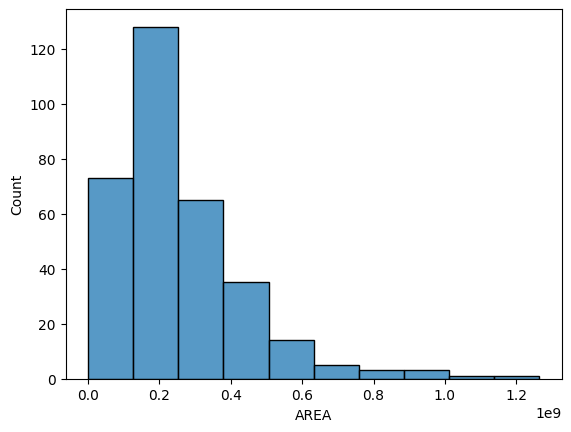

In [11]:
# A histogram of the area of the baronies. This shows that the majority of baronies are between 1000 and 2000 square
# kilometres in area. The largest barony is over 5000 square kilometres in area.

ax = sns.histplot(baronies2["AREA"], bins=10)
plt.show()

In [12]:
# Statistics of the Area column of the baronies2 GeoDataFrame.


baronies2["AREA"].describe()


count    3.280000e+02
mean     2.564140e+08
std      1.799790e+08
min      1.842020e+05
25%      1.297382e+08
50%      2.035736e+08
75%      3.378560e+08
max      1.264152e+09
Name: AREA, dtype: float64

What follows hereis a sequebce of statistical analysis and data visualization. The goal was to familiarise myself witht he tools, and gain some insights into the data. 

In [13]:
# Equal Interval classification of the baronies2 GeoDataFrame. This is a choropleth map classification method.

ei5 = mc.EqualInterval(baronies2["AREA"], k=5)
ei5

EqualInterval

           Interval              Count
--------------------------------------
[    184201.95,  252977695.81] |   201
( 252977695.81,  505771189.67] |   100
( 505771189.67,  758564683.53] |    19
( 758564683.53, 1011358177.39] |     6
(1011358177.39, 1264151671.25] |     2

In [14]:
# Fisher Jenks classification of the baronies2 GeoDataFrame. This is a binning method.

fj5 = mc.FisherJenks(baronies2["AREA"], k=5)
fj5


FisherJenks

           Interval              Count
--------------------------------------
[    184201.95,  167258868.32] |   126
( 167258868.32,  288197060.43] |   100
( 288197060.43,  445965219.37] |    61
( 445965219.37,  724670486.21] |    33
( 724670486.21, 1264151671.25] |     8

/var/folders/lk/44yhnrk92p95sjc8gdd7165h0000gn/T/ipykernel_23087/836222407.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


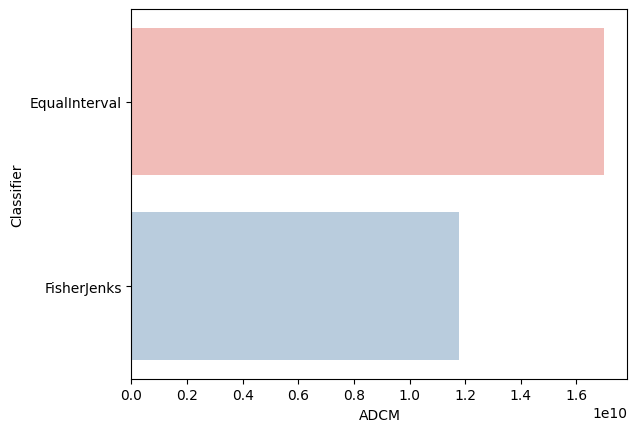

In [15]:
# Bunch classifier objects to see which one is best for the baronies2 GeoDataFrame. The best one is the one with the #lowest value


class5 = ei5, fj5
# Collect ADCM for each classifier
fits = np.array([c.adcm for c in class5])
# Convert ADCM scores to a DataFrame
adcms = pd.DataFrame(fits)
# Add classifier names
adcms["classifier"] = [c.name for c in class5]
# Add column names to the ADCM
adcms.columns = ["ADCM", "Classifier"]
ax = sns.barplot(
    y="Classifier", x="ADCM", data=adcms, palette="Pastel1"
)

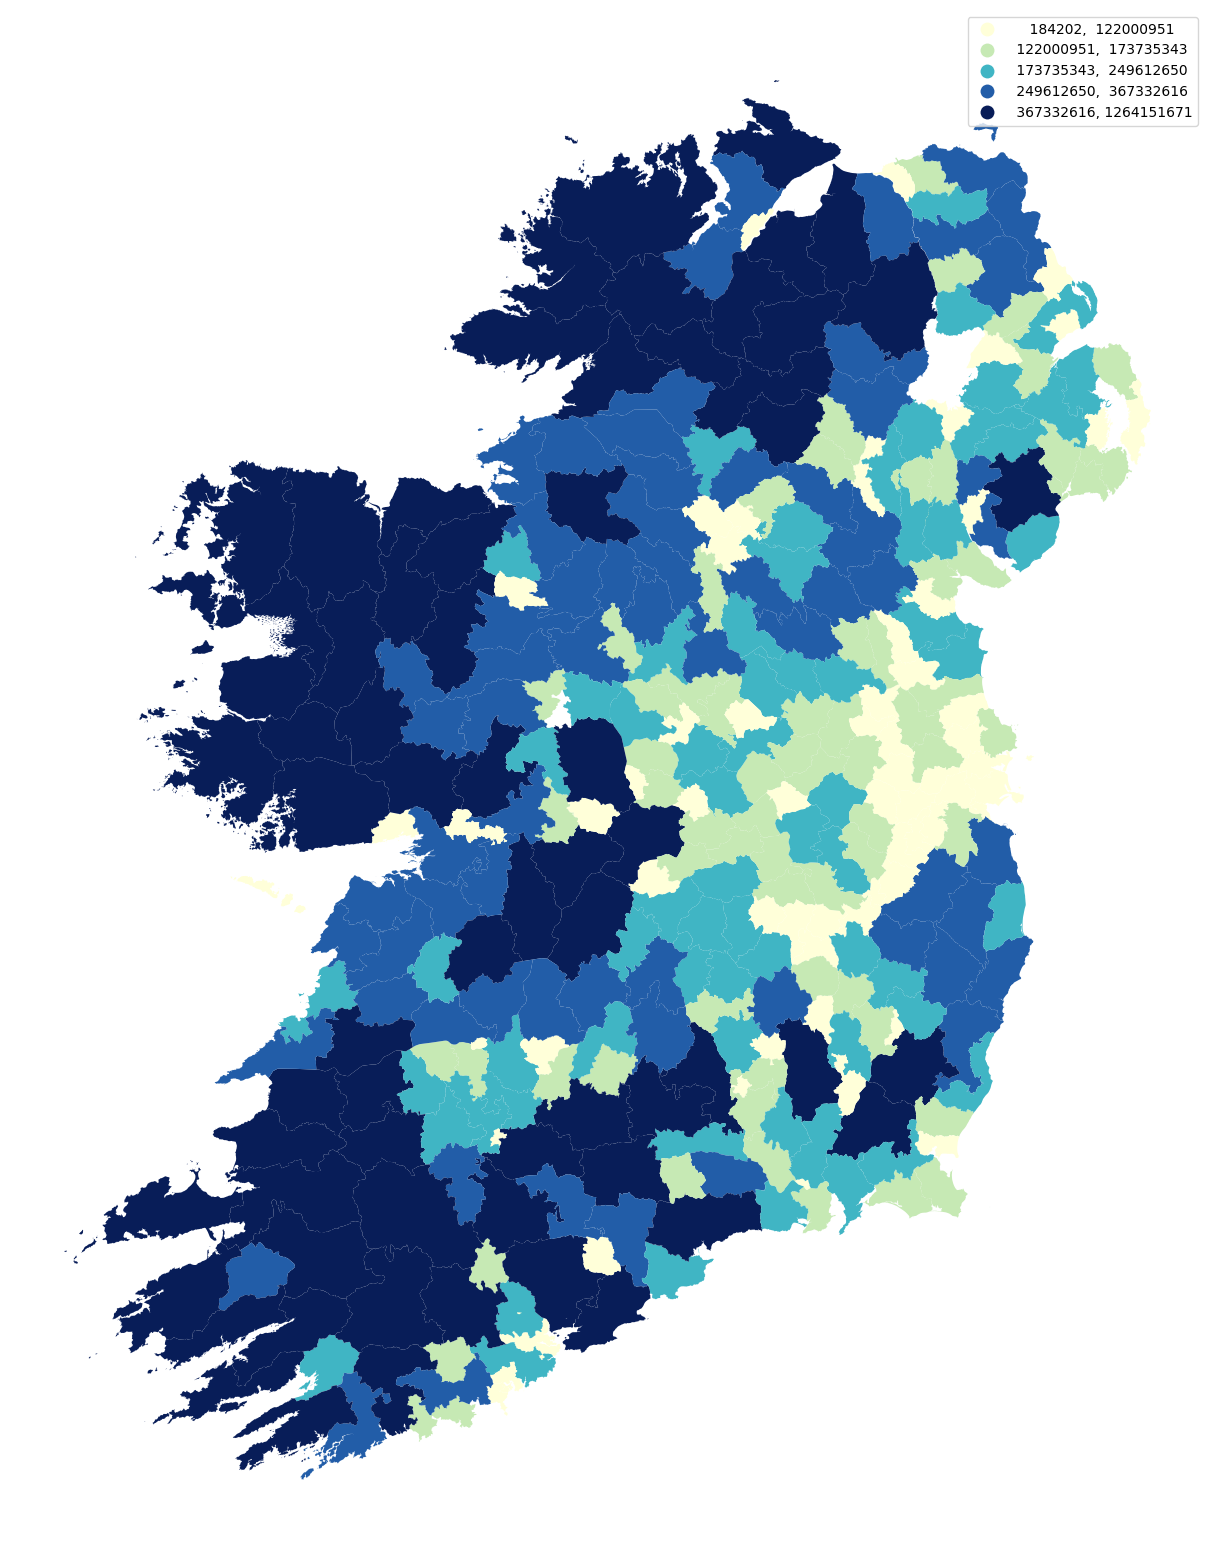

In [16]:
# Here is a choropleth map of the baronies2 GeoDataFrame using the Quantiles classification method. The map shows areas
# of similar size in similar colours. The legend shows the area in square kilometres of each colour. The map shows that
# the largest baronies are in mountainous areas in the west of Ireland. The smallest baronies are in the east of #Ireland, generally speaking.

ax = baronies2.plot (
    figsize=(20,20),
    column="AREA",
    scheme="Quantiles",
    cmap="YlGnBu",
    legend=True,
    legend_kwds={"fmt": "{:.0f}"}  # Remove decimals in legend
)
ax.set_axis_off();
    
plt.show()
             


Here is to establish a matrix or graph of contiguity between the territories. A Queen contiguity matrix is used, which is a binary matrix. The value 1 indicates that the two territories are neighbours, and 0 indicates that they are not.
Queen refers to the fact that the territories are considered to be neighbours if they share a common border or a common vertex.

In [17]:
w_queen = weights.contiguity.Queen.from_dataframe(baronies2, use_index=False)
w_queen

/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 265.
  warnings.warn(message)


In [18]:
# The weights matrix is a dictionary of lists. The keys are the baronies and the values are the baronies that are joined

w_queen.n
w_queen.histogram

[(0, 1),
 (1, 5),
 (2, 16),
 (3, 37),
 (4, 42),
 (5, 66),
 (6, 84),
 (7, 48),
 (8, 23),
 (9, 4),
 (10, 2)]

In [19]:
# Measure of density of spatial weights matrix (SW) is the average number of non-zero elements in the SW matrix

w_queen.pct_nonzero


1.6043277810826888

/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/libpysal/weights/weights.py:1493: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = gdf.loc[neighbors].centroid.apply(lambda p: (p.x, p.y))
/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/libpysal/weights/weights.py:1493: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = gdf.loc[neighbors].centroid.apply(lambda p: (p.x, p.y))
/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/libpysal/weights/weights.py:1493: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to 

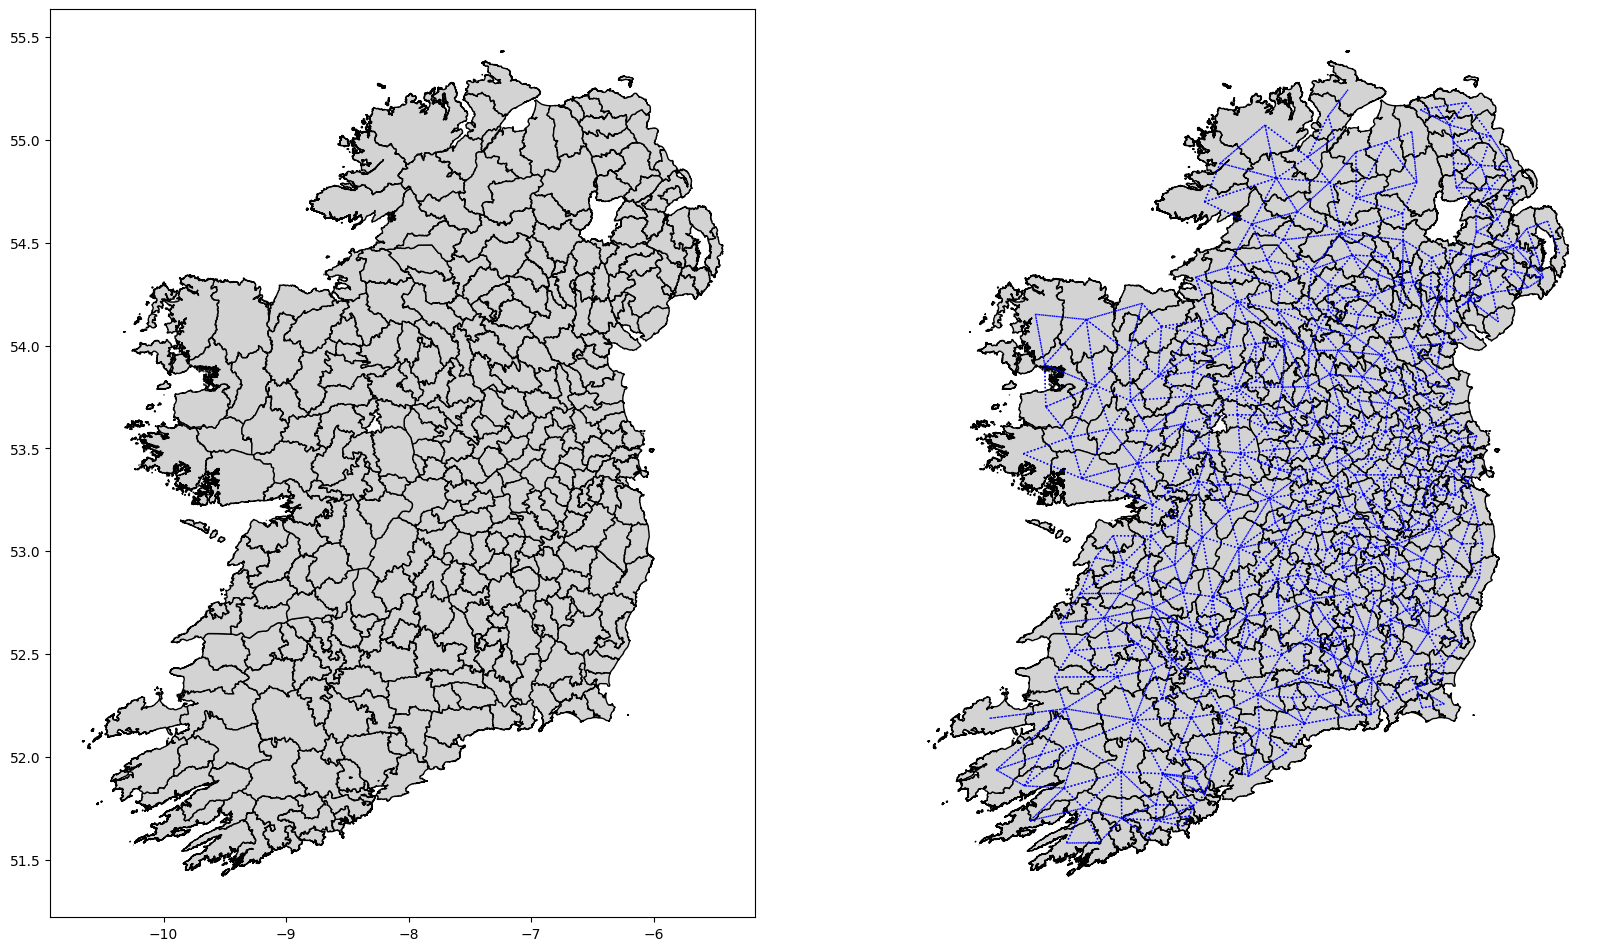

In [20]:
# Plot the spatial weights matrix, this is a matrix of the baronies and the baronies that are joined to them, Based on centroids of the baronies. 

f, axs = plt.subplots(1, 2, figsize=(20, 20))
for i in range(2):
    ax = baronies2.plot(
        edgecolor="k", facecolor="lightgray", ax=axs[i]
    )
w_queen.plot(
    baronies2, 
    ax = axs[i],
    edge_kws=dict(color="b", linestyle=":", linewidth=1),       
    node_kws=dict(marker="")),

axs[i].set_axis_off()
#axs[1].axis([0, 1, 0, 1])


In [78]:

# Number of joins in the spatial weights matrix

w_queen.s0

# Number of joins for each observation

w_queen.cardinalities



{0: 4,
 1: 6,
 2: 5,
 3: 6,
 4: 4,
 5: 7,
 6: 5,
 7: 3,
 8: 5,
 9: 6,
 10: 6,
 11: 6,
 12: 8,
 13: 2,
 14: 7,
 15: 5,
 16: 1,
 17: 6,
 18: 4,
 19: 5,
 20: 8,
 21: 4,
 22: 6,
 23: 4,
 24: 5,
 25: 6,
 26: 7,
 27: 1,
 28: 4,
 29: 4,
 30: 6,
 31: 5,
 32: 6,
 33: 2,
 34: 6,
 35: 5,
 36: 6,
 37: 7,
 38: 6,
 39: 7,
 40: 4,
 41: 6,
 42: 3,
 43: 5,
 44: 5,
 45: 4,
 46: 8,
 47: 5,
 48: 6,
 49: 8,
 50: 5,
 51: 8,
 52: 7,
 53: 4,
 54: 7,
 55: 8,
 56: 7,
 57: 3,
 58: 6,
 59: 6,
 60: 5,
 61: 5,
 62: 1,
 63: 6,
 64: 5,
 65: 5,
 66: 5,
 67: 3,
 68: 7,
 69: 2,
 70: 2,
 71: 6,
 72: 5,
 73: 4,
 74: 4,
 75: 6,
 76: 10,
 77: 9,
 78: 3,
 79: 4,
 80: 4,
 81: 3,
 82: 6,
 83: 8,
 84: 3,
 85: 5,
 86: 6,
 87: 3,
 88: 6,
 89: 3,
 90: 5,
 91: 6,
 92: 7,
 93: 6,
 94: 5,
 95: 5,
 96: 5,
 97: 6,
 98: 7,
 99: 7,
 100: 5,
 101: 5,
 102: 2,
 103: 7,
 104: 6,
 105: 4,
 106: 5,
 107: 5,
 108: 5,
 109: 8,
 110: 3,
 111: 7,
 112: 6,
 113: 6,
 114: 3,
 115: 7,
 116: 3,
 117: 2,
 118: 6,
 119: 6,
 120: 6,
 121: 5,
 122: 6,
 1

<Axes: ylabel='Frequency'>

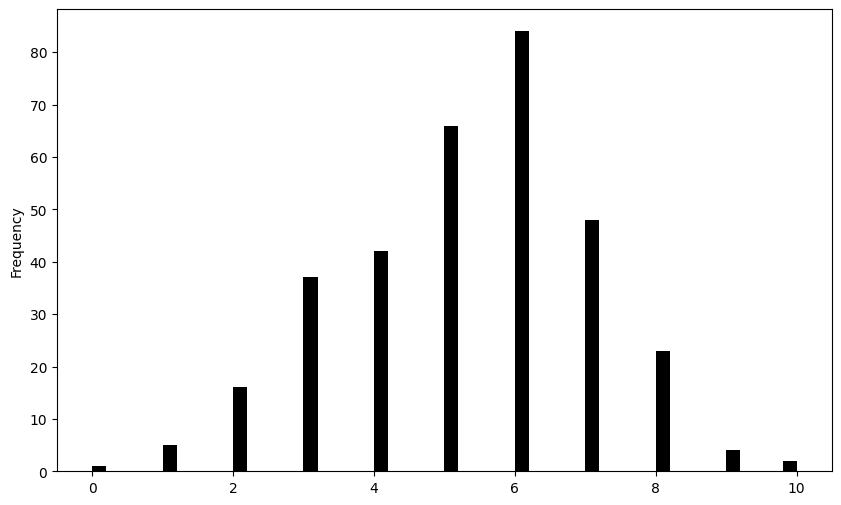

In [80]:
# Plot a histogram of the number of joins for each barony. 


import pandas as pd
pd.Series(w_queen.cardinalities).plot.hist(color = "k", bins=50, figsize=(10, 6))

In [81]:
# queen.n is the number of baronies in the spatial weights matrix

w_queen.n

328

Print the weights matrix. The matrix is structured as a dictionary, where each key represents an observation unit for example,  a spatial location or area), and the corresponding value is a list of weights indicating the spatial relationships #between the observation unit (row) and its neighbors (columns).

In [76]:
w_queen.weights

{0: [1.0, 1.0, 1.0, 1.0],
 1: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 2: [1.0, 1.0, 1.0, 1.0, 1.0],
 3: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 4: [1.0, 1.0, 1.0, 1.0],
 5: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 6: [1.0, 1.0, 1.0, 1.0, 1.0],
 7: [1.0, 1.0, 1.0],
 8: [1.0, 1.0, 1.0, 1.0, 1.0],
 9: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 10: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 11: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 12: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 13: [1.0, 1.0],
 14: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 15: [1.0, 1.0, 1.0, 1.0, 1.0],
 16: [1.0],
 17: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 18: [1.0, 1.0, 1.0, 1.0],
 19: [1.0, 1.0, 1.0, 1.0, 1.0],
 20: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 21: [1.0, 1.0, 1.0, 1.0],
 22: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 23: [1.0, 1.0, 1.0, 1.0],
 24: [1.0, 1.0, 1.0, 1.0, 1.0],
 25: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 26: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 27: [1.0],
 28: [1.0, 1.0, 1.0, 1.0],
 29: [1.0, 1.0, 1.0, 1.0],
 30: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
 31: [1.0, 1.

CIVIL PARISHES 11th and 12th CENTURIES


In [21]:
# readin the civil parishes file. This is a shapefile of the civil parishes of Ireland. A civil parish is a unit of land
# that was used for church administrative purposes in Ireland, and date to the 11th, and 12th centuries.

civil_parishes = gpd.read_file('/Users/mensab/Documents/GISMapFiles/civil_parishes')
print(civil_parishes.head())
print(civil_parishes.shape)
print(civil_parishes.columns)
civil_parishes.info()





      OSM_ID            NAME_TAG             NAME_GA      NAME_EN ALT_NAME  \
0 -6280381.0        Cill Imleach        Cill Imleach   Killemlagh      NaN   
1 -6267174.0  Baile na BhÃ³thair  Baile na BhÃ³thair  Ballinvoher      NaN   
2 -6266909.0              Ventry           FionntrÃ¡       Ventry      NaN   
3 -6266968.0             Kildrum        Cill Dromann      Kildrum      NaN   
4 -6266995.0              Dingle         An Daingean       Dingle      NaN   

  ALT_NAME_G OSM_USER              OSM_TIMEST ATTRIBUTIO LOGAINM_RE CO_NAMES  \
0        NaN    rorym  2016-06-02 18:27:43+02        NaN       1095    Kerry   
1        NaN    rorym  2016-05-29 17:10:32+02        NaN       1052    Kerry   
2        NaN    rorym  2016-05-29 14:47:44+02        NaN       1129    Kerry   
3        NaN    rorym  2016-05-29 14:56:14+02        NaN       1085    Kerry   
4        NaN    rorym  2016-05-29 15:09:47+02        NaN       1065    Kerry   

  CO_OSM_IDS                                      

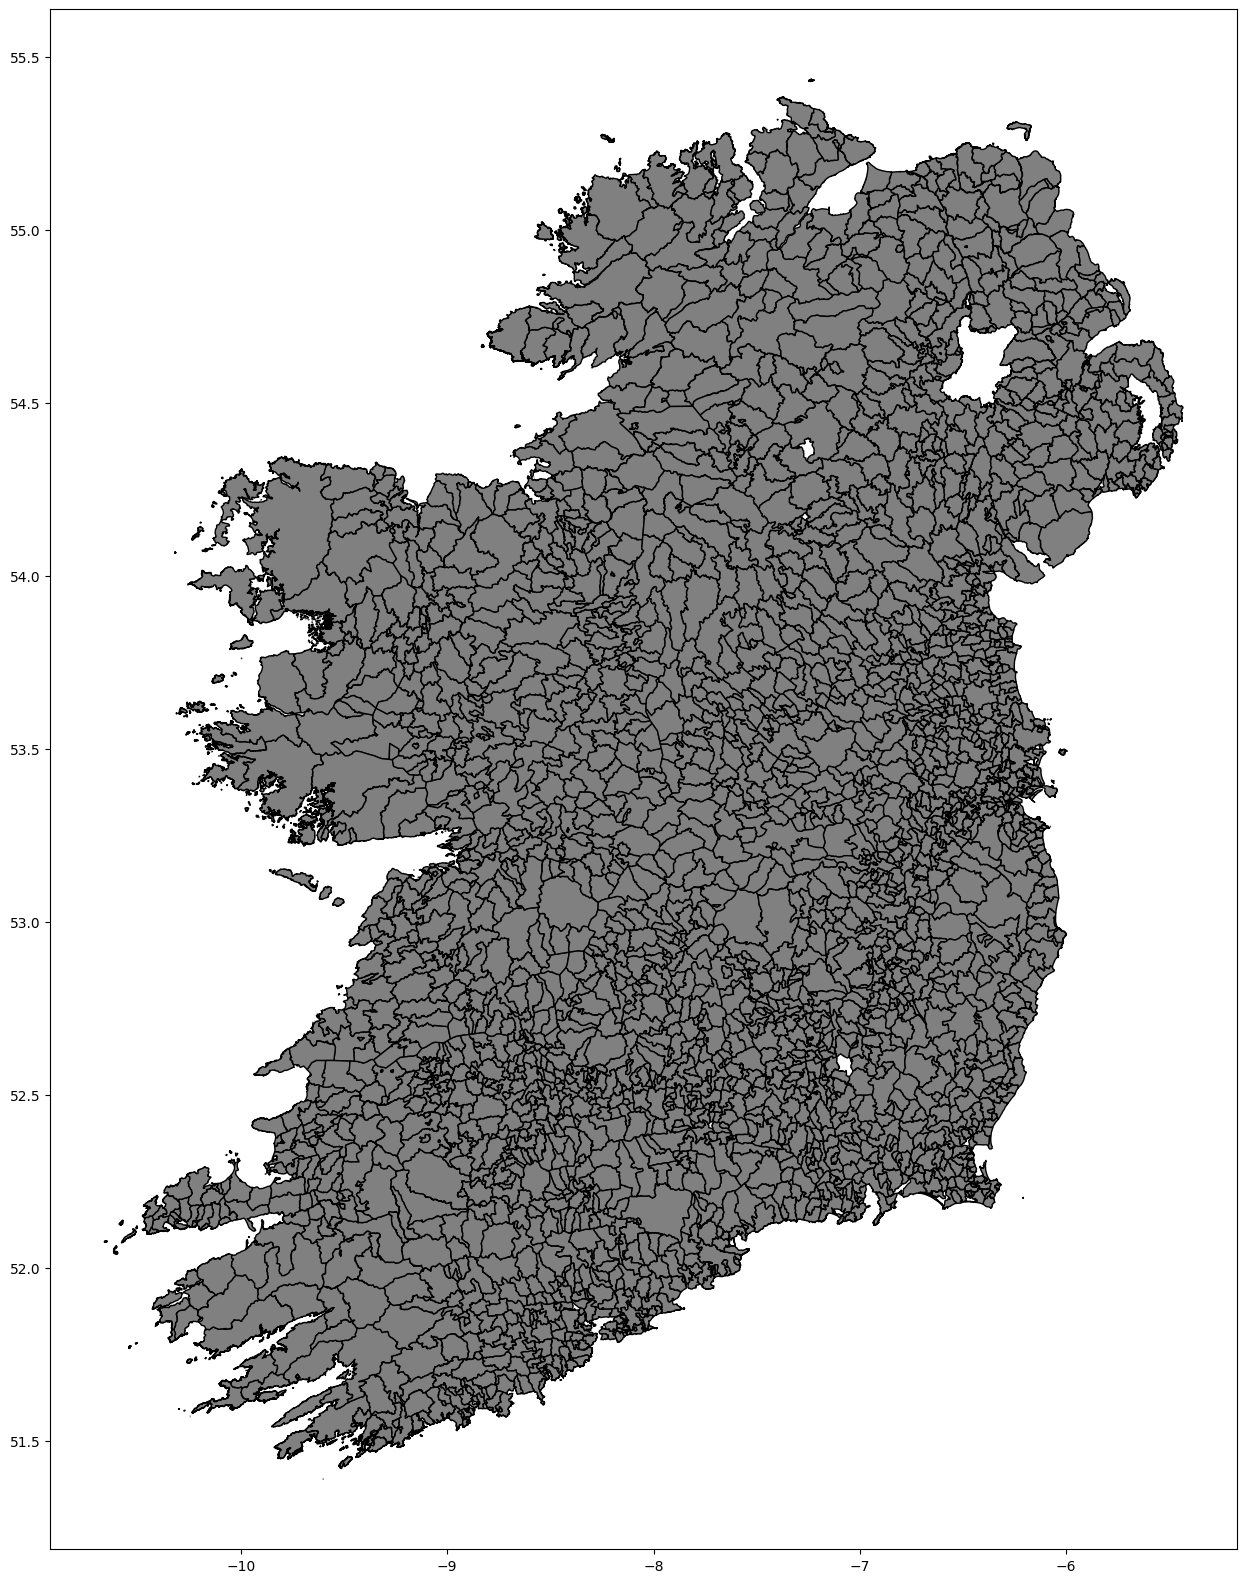

In [22]:
# Plot the civil parishes.

ax, fig = plt.subplots(figsize=(20,20))
civil_parishes.plot(ax=fig, color='gray', edgecolor='black')
plt.show()

#ax = geoplot.polyplot(civil_parishes, projection=geoplot.crs.Mercator())
#plt.show(ax)


In [1]:

civil_parishes.crs

civil_parishes.head()



NameError: name 'civil_parishes' is not defined

In [24]:
print(civil_parishes['AREA'].isnull().sum())


0


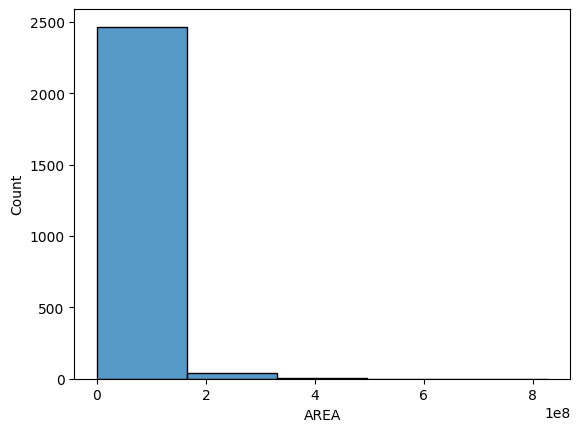

In [25]:
ax = sns.histplot(civil_parishes["AREA"], bins=5)
plt.show(ax)

In [26]:
civil_parishes["AREA"].describe()

count    2.509000e+03
mean     3.350960e+07
std      4.166367e+07
min      5.000580e+03
25%      1.015965e+07
50%      2.110558e+07
75%      4.228749e+07
max      8.277481e+08
Name: AREA, dtype: float64

In [27]:

ei5 = mc.EqualInterval(civil_parishes["AREA"], k=5)   # 5 equal intervals
ei5

EqualInterval

          Interval             Count
------------------------------------
[     5000.58, 165553620.04] |  2465
(165553620.04, 331102239.49] |    41
(331102239.49, 496650858.95] |     2
(496650858.95, 662199478.41] |     0
(662199478.41, 827748097.86] |     1

In [28]:
q5 = mc.Quantiles(civil_parishes["AREA"], k=5)   # 5 quantiles
q5

Quantiles

          Interval             Count
------------------------------------
[     5000.58,   8417043.08] |   502
(  8417043.08,  16361469.83] |   502
( 16361469.83,  27503739.15] |   501
( 27503739.15,  49750527.78] |   502
( 49750527.78, 827748097.86] |   502

In [29]:
msd = mc.StdMean(civil_parishes["AREA"])   # mean and standard deviation   
msd

StdMean

          Interval             Count
------------------------------------
(        -inf, -49817740.03] |     0
(-49817740.03,  -8154071.03] |     0
( -8154071.03,  75173266.98] |  2268
( 75173266.98, 116836935.98] |   150
(116836935.98, 827748097.86] |    91

In [30]:
mb5 = mc.MaximumBreaks(civil_parishes["AREA"], k=5)   # 5 maximum breaks
mb5

MaximumBreaks

          Interval             Count
------------------------------------
[     5000.58, 307648226.95] |  2505
(307648226.95, 370026068.77] |     1
(370026068.77, 430250106.00] |     1
(430250106.00, 635474161.01] |     1
(635474161.01, 827748097.86] |     1

In [31]:
bp = mc.BoxPlot(civil_parishes["AREA"])   # box plot
bp

BoxPlot

          Interval             Count
------------------------------------
(        -inf, -38032114.80] |     0
(-38032114.80,  10159648.13] |   628
( 10159648.13,  21105580.28] |   627
( 21105580.28,  42287490.08] |   627
( 42287490.08,  90479253.01] |   467
( 90479253.01, 827748097.86] |   160

In [32]:
ht = mc.HeadTailBreaks(civil_parishes["AREA"])   # head/tail breaks
ht

HeadTailBreaks

          Interval             Count
------------------------------------
[     5000.58,  33509597.97] |  1688
( 33509597.97,  72310179.16] |   567
( 72310179.16, 124541546.98] |   172
(124541546.98, 194170888.86] |    55
(194170888.86, 274937756.41] |    21
(274937756.41, 430963572.04] |     4
(430963572.04, 635474161.01] |     1
(635474161.01, 827748097.86] |     1

In [33]:
np.random.seed(12345)
jc5 = mc.JenksCaspall(civil_parishes["AREA"], k=5)   # Jenks-Caspall
jc5

JenksCaspall

          Interval             Count
------------------------------------
[     5000.58,  13422310.96] |   827
( 13422310.96,  30077932.77] |   754
( 30077932.77,  57822683.25] |   544
( 57822683.25, 118600386.22] |   295
(118600386.22, 827748097.86] |    89

In [34]:
np.random.seed(12345)
fj5 = mc.FisherJenks(civil_parishes["AREA"], k=5)   # Fisher-Jenks
fj5


FisherJenks

          Interval             Count
------------------------------------
[     5000.58,  29703382.30] |  1575
( 29703382.30,  72249410.50] |   680
( 72249410.50, 159307140.57] |   207
(159307140.57, 443200224.15] |    46
(443200224.15, 827748097.86] |     1

In [35]:
# mp5 = mc.MaxP(civil_parishes["AREA"], k=5)   # Max-p
# mp5

/var/folders/lk/44yhnrk92p95sjc8gdd7165h0000gn/T/ipykernel_23087/2719562733.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


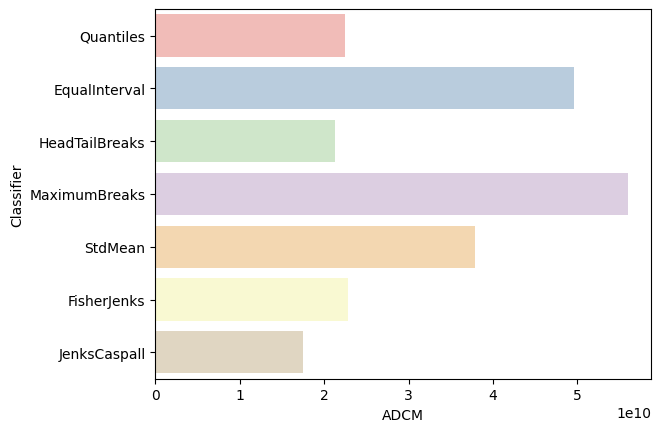

In [36]:
# Bunch classifier objects
class5 = q5, ei5, ht, mb5, msd, fj5, jc5
# Collect ADCM for each classifier
fits = np.array([c.adcm for c in class5])
# Convert ADCM scores to a DataFrame
adcms = pd.DataFrame(fits)
# Add classifier names
adcms["classifier"] = [c.name for c in class5]
# Add column names to the ADCM
adcms.columns = ["ADCM", "Classifier"]
ax = sns.barplot(
    y="Classifier", x="ADCM", data=adcms, palette="Pastel1"
)

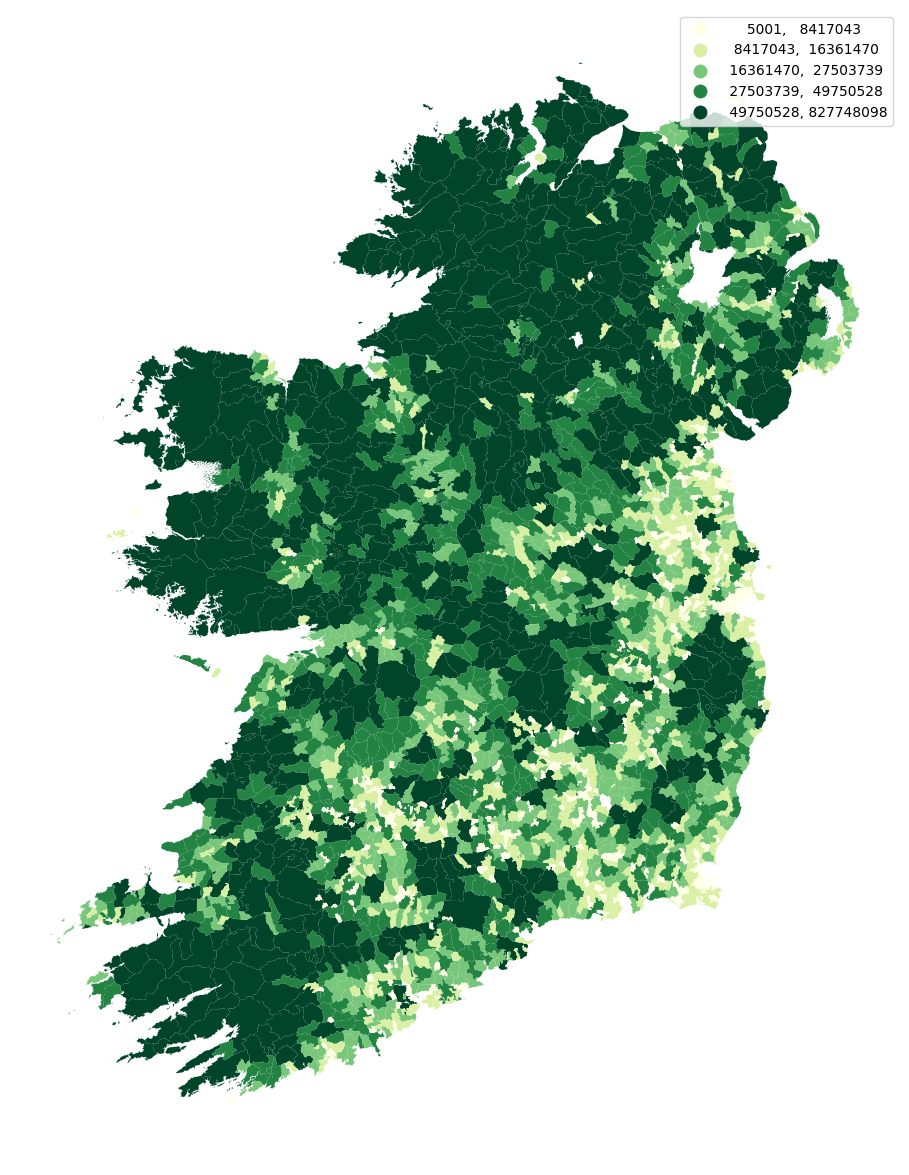

In [37]:
ax = civil_parishes.plot(
    figsize=(15, 15),
    column="AREA",  # Data to plot
    scheme="Quantiles",  # Classification scheme
    cmap="YlGn",  # Color palette
    legend=True,  # Add legend
    legend_kwds={"fmt": "{:.0f}"},  # Remove decimals in legend
)
ax.set_axis_off();

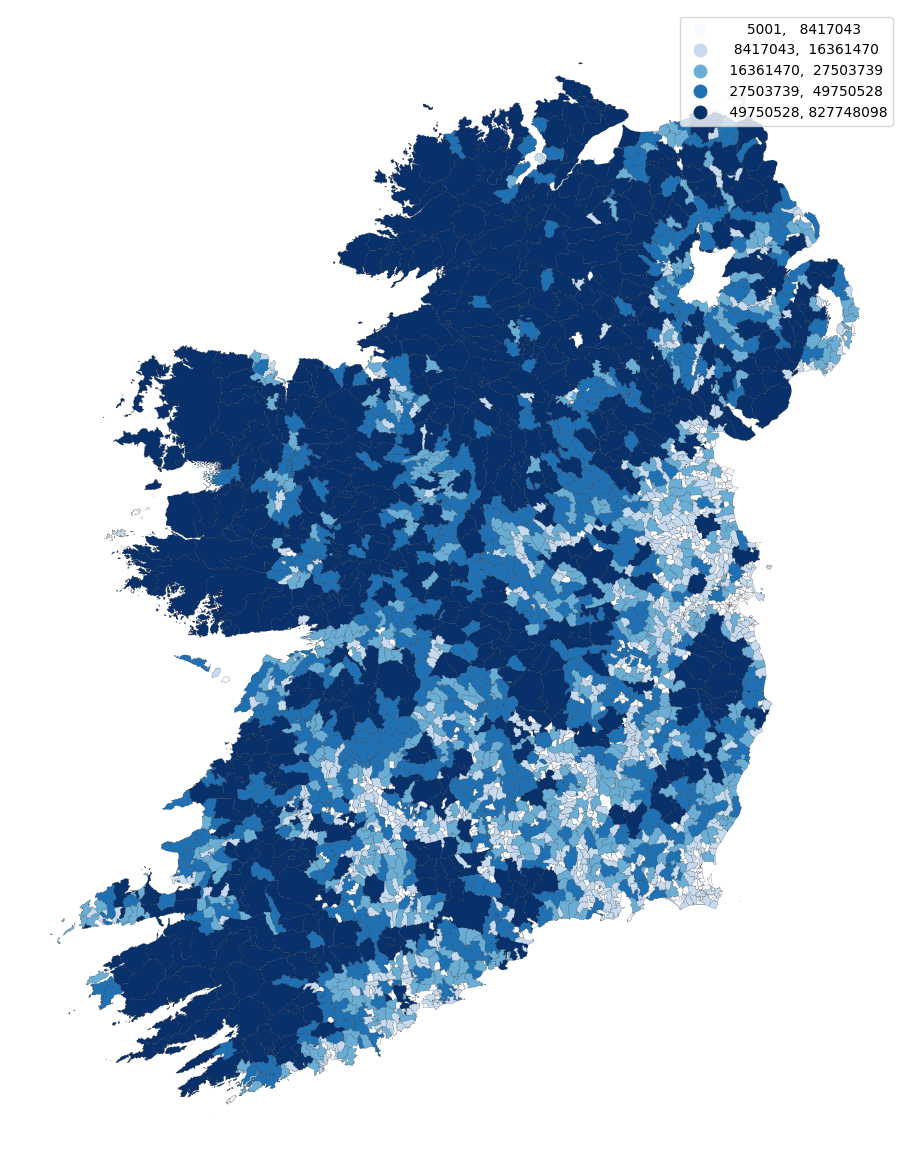

In [38]:
ax = civil_parishes.plot(
    figsize=(15, 15),
    column="AREA",  # Data to plot
    scheme="Quantiles",  # Classification scheme
    cmap="Blues",  # Color palette
    edgecolor="k",  # Borderline color
    linewidth=0.1,  # Borderline width
    legend=True,  # Add legend
    legend_kwds={
        "fmt": "{:.0f}"
    },  # Remove decimals in legend (for legibility)
)
ax.set_axis_off();

Townlands GeoDataFrame

In [39]:
# read in the townlands file. This is a shapefile of the townlands of Ireland. A townland is the smallest administrative
# unit of land in Ireland. There are over 60,000 townlands in Ireland.

townlands = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Townlands_-_OSi_National_Statutory_Boundaries_Generalised_shp')
# townlands = townlands.to_crs('EPSG:4326')
print(townlands.head())
print(townlands.shape)
townlands.info()



    TD_ID        ENGLISH                GAEILGE LOGAINM_ID  \
0  100169       BARKMILL     Muileann na Coiste      28588   
1   21628  MULLACROGHERY  Mullach an Chrochaire       4902   
2   62511         ISLAND             An tOileán      19877   
3   10232       CRANNAGH           An Chrannach       3448   
4  191754       PARKMORE                    NaN      42481   

                                   GUID GAELTACHT       CONTAE     COUNTY  \
0  2ae19629-9176-13a3-e055-000000000001         N        Laois      LAOIS   
1  2ae19629-e8ab-13a3-e055-000000000001         N    An Cabhán      CAVAN   
2  2ae1962a-39ff-13a3-e055-000000000001         N     Gaillimh     GALWAY   
3  2ae19629-9965-13a3-e055-000000000001         N  Ceatharlach     CARLOW   
4  2ae19629-d32b-13a3-e055-000000000001         N   Ros Comáin  ROSCOMMON   

   PROVINCE  CENTROID_X  CENTROID_Y        AREA  OBJECTID    Shape__Are  \
0  Leinster   641148.65   704734.39  1017302.78         1  1.009791e+06   
1    Ulster   

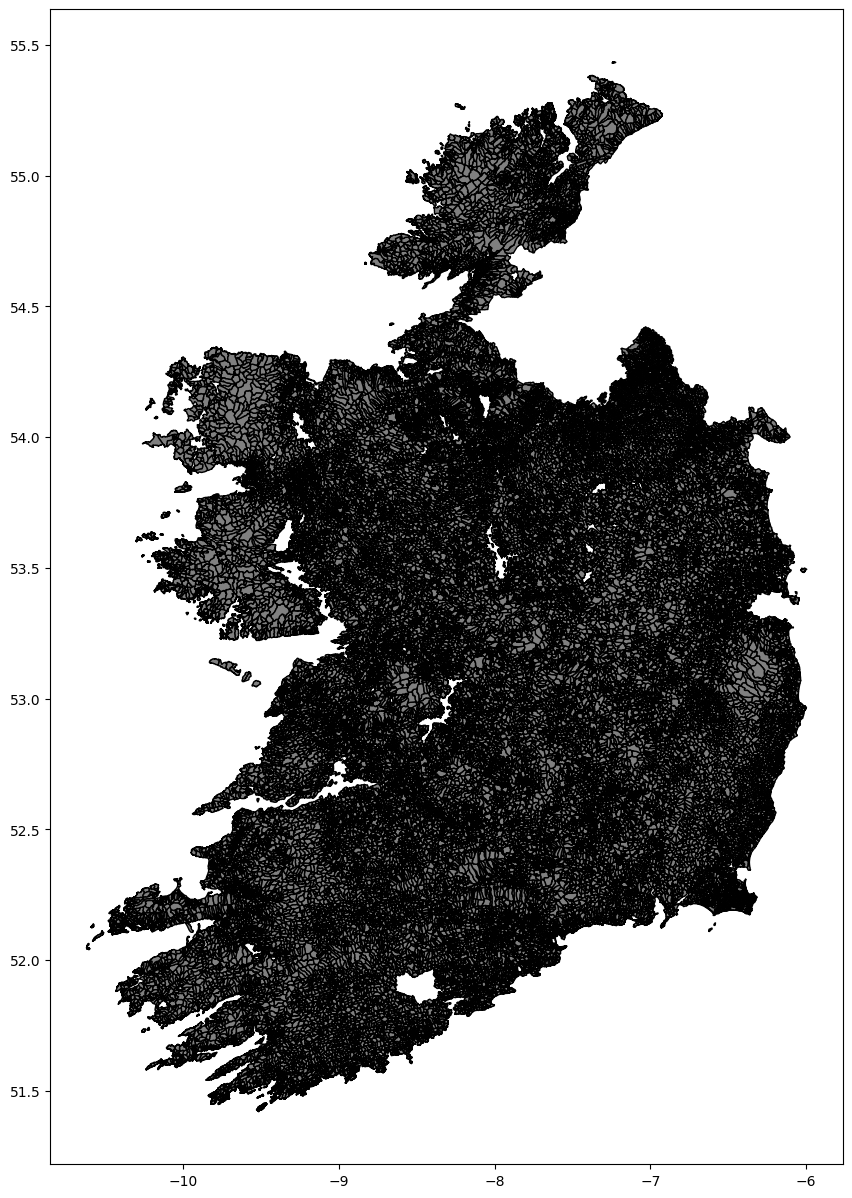

In [40]:
# Plot the townlands.

ax, fig = plt.subplots(figsize=(15,15))
townlands.plot(ax=fig, color='gray', edgecolor='black')
plt.show()

# Get the GeoDataFrame extent and use it to set the limits
#xmin, ymin, xmax, ymax = townlands.total_bounds
#fig, ax = plt.subplots()
#townlands.plot(ax=ax)
#ax.set_xlim([xmin, xmax])
#ax.set_ylim([ymin, ymax])
#plt.show()

#ax = geoplot.polyplot(townlands, projection=geoplot.crs.Mercator())
#plt.show(ax)


In [41]:
townlands.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

TII is Transport Infrastructure Ireland, and it is the national roads authority. The dataset contains the coordinates of archaeological sites along the road network in Ireland. The dataset is in the form of a shapefile, which is a geospatial vector data format for geographic information system (GIS) software.

In [42]:

tii_data = gpd.read_file("zip:////Users/mensab/Documents/GISMapFiles/TIIArchaeology.zip")
tii_data



,dc_identif,url,Townland,dc_title,dc_publish,dc_creator,dc_creat_1,dc_creat_2,dc_creat_3,dc_subject,dc_subje_1,dc_subje_2,dc_subje_3,dc_subje_4,dc_contrib,ITM_X,ITM_Y,Latitude,Longitude,geometry
0,00E0810,https://repository.dri.ie/catalog/0000cd770,Sheephouse,"Archaeological excavation report, 00E0810 Shee...",Transport Infrastructure Ireland,"Moore, Declan",NaN,NaN,NaN,Ring-ditch,Kiln - corn-drying,Habitation site,Field system,NaN,Irish Archaeological Consultancy Ltd.,705948.11,774647.57,53.710747,-6.395089,POINT (705948.110 774647.570)
1,03E0158,https://repository.dri.ie/catalog/0000cd788,Balregan,"Archaeological excavation report, 03E0158 Site...",Transport Infrastructure Ireland,"Delaney, Shane",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Irish Archaeological Consultancy Ltd.,702735.13,810103.95,54.029886,-6.431870,POINT (702735.130 810103.950)
2,E3047,https://repository.dri.ie/catalog/0000cd79j,Leshamstown,"Archaeological excavation report, E3047 Lesha...",Transport Infrastructure Ireland,"Schweitzer, Holger","Ginn, Vicky",NaN,NaN,Pit,Burnt mound,NaN,NaN,NaN,Archaeological Consultancy Services Ltd,695320.17,751836.57,53.507868,-6.562996,POINT (695320.170 751836.570)
3,E3187,https://repository.dri.ie/catalog/0000cd809,Derver,"Archaeological excavation report, E3187 Derve...",Transport Infrastructure Ireland,"Reilly, Stuart","Ginn, Vicky",NaN,NaN,Pit,Hearth,NaN,NaN,NaN,Archaeological Consultancy Services Ltd,666275.63,780427.55,53.769222,-6.994678,POINT (666275.630 780427.550)
4,02E1145,https://repository.dri.ie/catalog/0000cd81k,Towlaght,"Archaeological excavation report, 02E1145 Tow...",Transport Infrastructure Ireland,"Linnane, Stephen",NaN,NaN,NaN,Fulacht fia,Pit,NaN,NaN,NaN,Archaeological Consultancy Services Ltd.,664552.74,743658.51,53.460778,-7.132455,POINT (664552.740 743658.510)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1625,02E1144,https://repository.dri.ie/catalog/zs269q242,Griffinstown,"Archaeological excavation report, 02E1144 Gri...",Transport Infrastructure Ireland,"Linnane, Stephen",NaN,NaN,NaN,Metalworking site,Kiln,NaN,NaN,NaN,Archaeological Consultancy Services Ltd.,657611.26,745986.05,53.460778,-7.132455,POINT (657611.260 745986.050)
1626,E2440,https://repository.dri.ie/catalog/zs269q25b,Ballykeeran,"Archaeological excavation report, E2440 Bally...",Transport Infrastructure Ireland,"Wilkins, Brendon",NaN,NaN,NaN,Cist,Ring-ditch,Cremated remains,Cremated remains,NaN,Headland Archaeology Ltd,560379.29,722806.53,53.254138,-8.593745,POINT (560379.290 722806.530)
1627,E3874,https://repository.dri.ie/catalog/zs269q26m,Ballynaclogh,"Archaeological excavation report, E3874 Bally...",Transport Infrastructure Ireland,"Maginness, Clare","O'Dowd, Jean",NaN,NaN,Prehistoric site - lithic scatter,Settlement platform,Structure - peatland,Road - class 3 togher,NaN,The Archaeology Company,574088.33,726504.66,53.288218,-8.388612,POINT (574088.330 726504.660)
1628,03E1458,https://repository.dri.ie/catalog/zs269q331,Ballynamona,"Archaeological excavation report, 03E1458 Bal...",Transport Infrastructure Ireland,"Cotter, Eamonn",NaN,NaN,NaN,Pit,NaN,NaN,NaN,NaN,Archaeological Consultancy Services Ltd,581781.34,599792.07,52.149672,-8.266217,POINT (581781.340 599792.070)


In [43]:
tii_data.columns


Index(['dc_identif', 'url', 'Townland', 'dc_title', 'dc_publish', 'dc_creator',
       'dc_creat_1', 'dc_creat_2', 'dc_creat_3', 'dc_subject', 'dc_subje_1',
       'dc_subje_2', 'dc_subje_3', 'dc_subje_4', 'dc_contrib', 'ITM_X',
       'ITM_Y', 'Latitude', 'Longitude', 'geometry'],
      dtype='object')

load amd visualise archaeological data

Next is loading the National Monuments Service dataset. This dataset contains the coordinates of archaeological sites in Ireland. The dataset is in the form of a shapefile. 

In [3]:

monuments_points = gpd.read_file("zip:///Users/mensab/Documents/GISMapFiles/NMS_OpenData_20230623_shp.zip")
monuments_points


,OID_,OBJECTID,ENTITY_ID,CLASS_CODE,SMRS,COUNTY,TOWNLAND,COUNTY_ID,ZONE_ID,ITM_E,ITM_N,LATITUDE,LONGITUDE,MONUMENT_T,FIRST_EDIT,LATEST_EDI,WEBSITE_LI,WEB_NOTES,geometry
0,1,1,CL00557,WETO,CL005-135----,CLARE,GLENINSHEEN,4,R126607,523006,702345,53.066178,-9.148800,Megalithic tomb - wedge tomb,NaN,Not indicated,https://maps.archaeology.ie/HistoricEnvironmen...,See linked document with details from Ruaidhrí...,POINT (523006.000 702345.000)
1,2,2,CL00558,WETO,CL005-136001-,CLARE,GLENINSHEEN,4,R126614,523061,702431,53.066959,-9.148001,Megalithic tomb - wedge tomb,NaN,Indicated (1916),https://maps.archaeology.ie/HistoricEnvironmen...,See linked document with details from Ruaidhrí...,POINT (523061.000 702431.000)
2,3,3,CL00559,NOAN,CL005-136002-,CLARE,GLENINSHEEN,4,NaN,0,0,46.488181,-15.817314,Redundant record,NaN,NaN,https://maps.archaeology.ie/HistoricEnvironmen...,A fulacht fia was recorded in this townland in...,POINT (0.000 0.000)
3,4,4,CL00560,HOWE,CL005-137----,CLARE,GLENINSHEEN,4,R188511,522963,702981,53.071887,-9.149594,Ritual site - holy well,NaN,'Holy Well' (1916),https://maps.archaeology.ie/HistoricEnvironmen...,The Archaeological Survey of Ireland (ASI) is ...,POINT (522963.000 702981.000)
4,5,5,CL00561,ENCL,CL005-138----,CLARE,GLENSLEADE,4,R126542,523255,701680,53.060239,-9.144928,Enclosure,Not indicated,Indicated (1916),https://maps.archaeology.ie/HistoricEnvironmen...,Situated on the S slope of a slight ridge with...,POINT (523255.000 701680.000)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
162519,162520,162520,KD03378,RGDH,KD011-075----,KILDARE,CASTLETOWN,13,R192421,697856,735145,53.357448,-6.529970,Ring-ditch,Not indicated,Not indicated,https://maps.archaeology.ie/HistoricEnvironmen...,Reported by Jean-Charles Caillere; in tillage ...,POINT (697856.000 735145.000)
162520,162521,162521,KK06300,ENCL,KK031-106----,KILKENNY,BAWNHUBBAMADDEREEN,14,R192422,648593,638235,52.493353,-7.284427,Enclosure,Not indicated,Not indicated,https://maps.archaeology.ie/HistoricEnvironmen...,In tillage. It is located immediately NE of a ...,POINT (648593.000 638235.000)
162521,162522,162522,KK06301,ENCL,KK019-147----,KILKENNY,GARRINCREEN,14,R192424,652516,656984,52.661492,-7.223692,Enclosure,Not indicated,Not indicated,https://maps.archaeology.ie/HistoricEnvironmen...,In tillage. An oval enclosure (dims. c. 63m NW...,POINT (652516.000 656984.000)
162522,162523,162523,DG04008,PLAM,DG018-042----,DONEGAL,DRUMFAD LOWER,7,NaN,623136,936956,55.179339,-7.636779,Platform,Not indicated,Not indicated,https://maps.archaeology.ie/HistoricEnvironmen...,"In pasture, located on top of a broad low hill...",POINT (623136.000 936956.000)


In [4]:
# Number of categories in the monument type column.

unique_monuments = monuments_points['MONUMENT_T'].unique()
unique_monuments
print (len(unique_monuments))


477


In [5]:
# DATATYPE of the monument type column.

type(monuments_points.geometry[1])



shapely.geometry.point.Point

In [6]:
monuments_points.columns

Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'geometry'],
      dtype='object')

In [7]:
monuments_points['ENTITY_ID'].value_counts()


ENTITY_ID
DU05051    2
MA09436    2
CL00557    1
OF02422    1
OF02416    1
          ..
GA13532    1
GA13533    1
GA13536    1
GA13537    1
CL09984    1
Name: count, Length: 162522, dtype: int64

In [8]:
# Numbers of monuments of each type. The most common monument type is a ringfort, with 10,000 monuments.

all_monuments_values = monuments_points['MONUMENT_T'].value_counts()
all_monuments_values

MONUMENT_T
Ringfort - rath                         25947
Enclosure                               16487
Redundant record                        11877
Fulacht fia                              6624
Hut site                                 4909
                                        ...  
Religious house - Friars of the Sack        1
Tram depot                                  1
Charnel house                               1
Milestone (present location)                1
Lock                                        1
Name: count, Length: 476, dtype: int64

In [9]:
# List all the individual monuments that have only one entry

monuments_points['MONUMENT_T'].value_counts()[monuments_points['MONUMENT_T'].value_counts() == 1]


MONUMENT_T
Pill-box                                               1
Asylum                                                 1
Ritual site - holy/saint's stone (present location)    1
Causewayed enclosure                                   1
Electricity generating station                         1
Religious house - Order of St Thomas of Acon           1
Boundary stone (present location)                      1
Religious house - Monks of the Order of Tiron          1
Religious house - Cluniac monks                        1
Tomb - unclassified (present location)                 1
Sundial (present location)                             1
Cursing stone (present location)                       1
Mine - barytes                                         1
Threshing floor                                        1
Hydro                                                  1
Strip Lynchets                                         1
Coach house                                            1
Creamery            

In [14]:
# A considerable amount of information on the monumnets is contained in the WEB_NOTES column. This column contains
# information on the monument type, the location of the monument, and the date of the monument. This information is
# contained in the form of a string. This string can be split into separate columns to make the information more
# accessible. The first step is to convert the WEB_NOTES column to a list.


web_notes = monuments_points["WEB_NOTES"]
print(web_notes)

0         See linked document with details from Ruaidhrí...
1         See linked document with details from Ruaidhrí...
2         A fulacht fia was recorded in this townland in...
3         The Archaeological Survey of Ireland (ASI) is ...
4         Situated on the S slope of a slight ridge with...
                                ...                        
162519    Reported by Jean-Charles Caillere; in tillage ...
162520    In tillage. It is located immediately NE of a ...
162521    In tillage. An oval enclosure (dims. c. 63m NW...
162522    In pasture, located on top of a broad low hill...
162523    Reported by Conn Herriott. Visible on GeoHive ...
Name: WEB_NOTES, Length: 162524, dtype: object


In [13]:


#  Access the record at index 2 (for example):
selected_record = monuments_points.iloc[8]

# Now, you can access individual columns within the selected record, e.g., "WEB_NOTES":
web_notes_value = selected_record["WEB_NOTES"]

# Print the value of the "WEB_NOTES" column for the selected record
print(web_notes_value)

The Archaeological Survey of Ireland (ASI) is in the process of providing information on all monuments on The Historic Environment Viewer (HEV). Currently the information for this record has not been uploaded.  To access available  information for resear


In [16]:
# Web Notes data type

type(web_notes[4])


str

Begin removing monuments that are after the cutoff of circa  1600 AD. First select only those in the four counties of interest. Then remove those that are after the cutoff date.

<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:2157


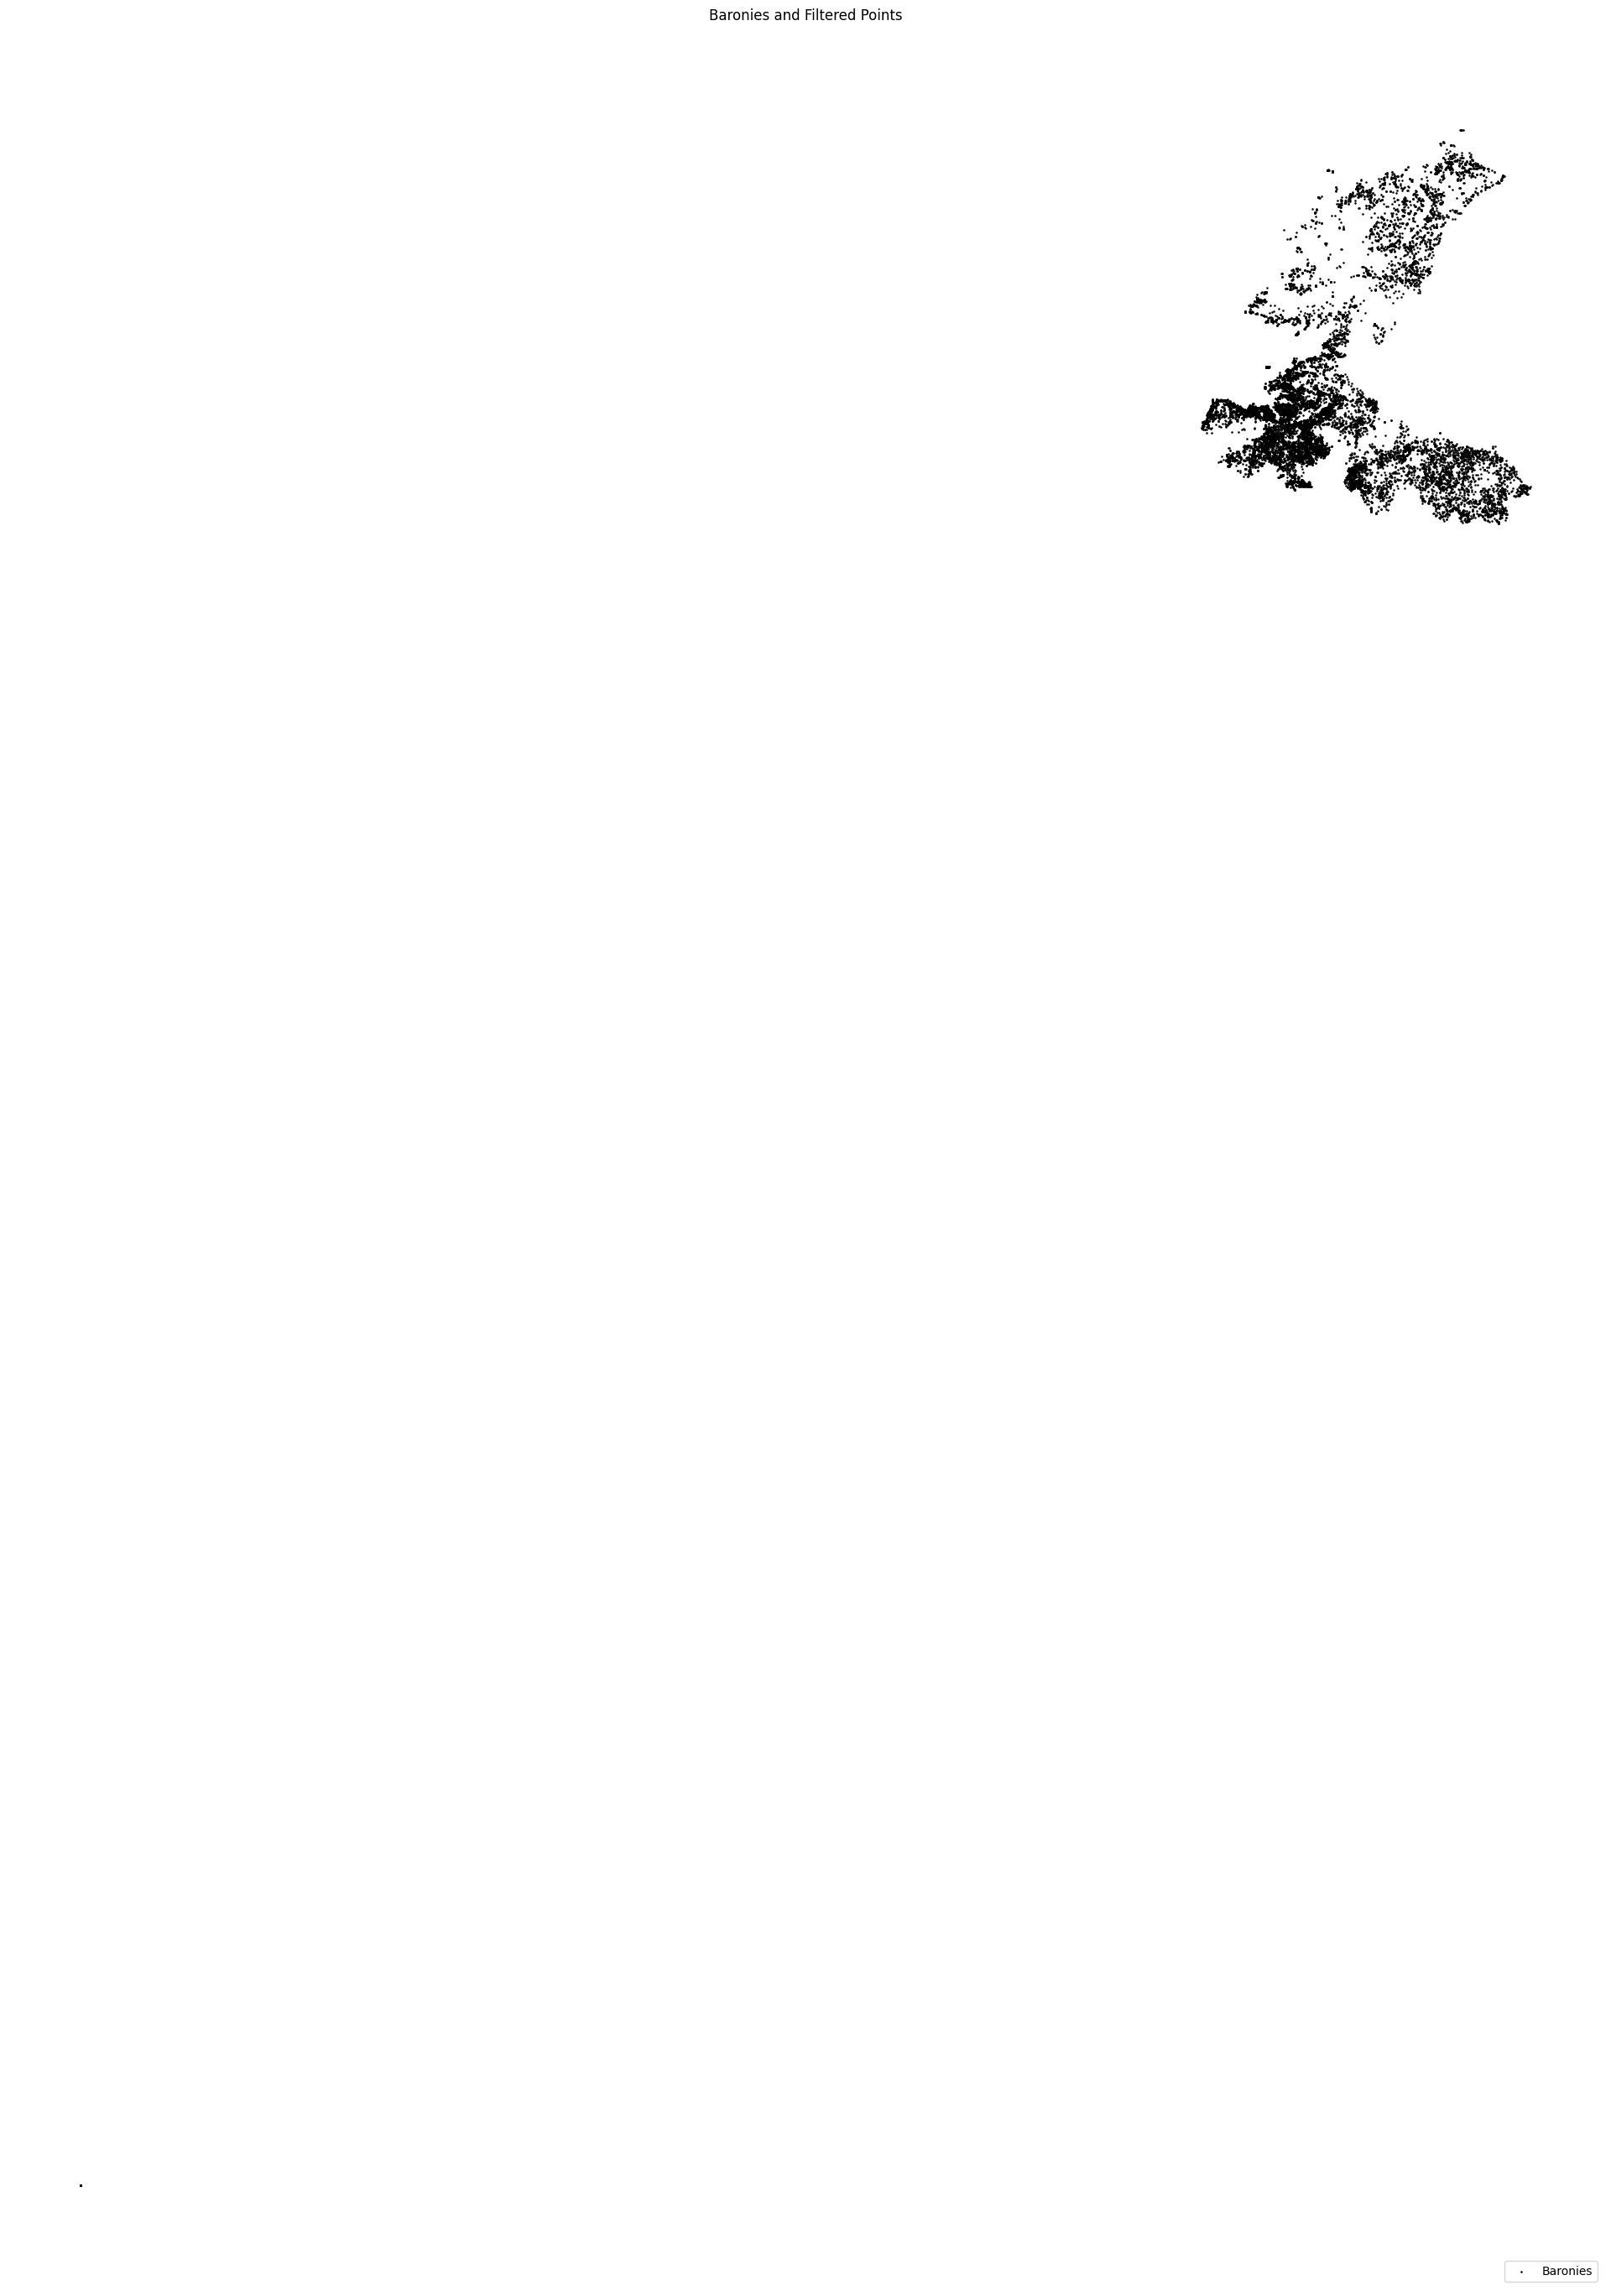

In [17]:
#baronies = gpd.read_file("zip:///Users/mensab/Documents/GISMapFiles/#Baronies_-_OSi_National_Statutory_Boundaries_-_Generalised_20m-shp.zip")
#sligo_donegal = baronies[baronies['COUNTY'].isin(['SLIGO', 'DONEGAL', 'LEITRIM'])]

#print(sligo_donegal.__class__)  
#print(sligo_donegal.crs)

# Filter the monuments by first selecting only the four counties of interest, Sligo, Donegal, Leitrim, and Cavan.


filtered_points = monuments_points[monuments_points['COUNTY'].isin(['SLIGO', 'DONEGAL', 'LEITRIM', 'CAVAN'])]
print(filtered_points.__class__)
print(filtered_points.crs)

# Plot the baronies and the filtered points. The baronies are in grey, and the filtered points are in black.

fig, ax = plt.subplots(figsize=(35, 35))
#sligo_donegal.plot(ax=ax, color = 'grey', )  # Adjust alpha for transparency
filtered_points.plot(ax=ax, color='black', markersize=0.7)
ax.set_title('Baronies and Filtered Points')
ax.set_axis_off()


#ax.set_xlim(0, 5)  # Adjust these values for your desired extent
#ax.set_ylim(52, 56)   # Adjust these values for your desired extent

# Adjust the position of the legend to the desired location (e.g., 'lower right')
ax.legend(['Baronies', 'Filtered Points'], loc='lower right')
ax.autoscale()

plt.show()




In [18]:
filtered_points.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 16328 entries, 246 to 162522
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OID_        16328 non-null  int64   
 1   OBJECTID    16328 non-null  int64   
 2   ENTITY_ID   16328 non-null  object  
 3   CLASS_CODE  16328 non-null  object  
 4   SMRS        16328 non-null  object  
 5   COUNTY      16328 non-null  object  
 6   TOWNLAND    16327 non-null  object  
 7   COUNTY_ID   16328 non-null  int64   
 8   ZONE_ID     13960 non-null  object  
 9   ITM_E       16328 non-null  int64   
 10  ITM_N       16328 non-null  int64   
 11  LATITUDE    16328 non-null  float64 
 12  LONGITUDE   16328 non-null  float64 
 13  MONUMENT_T  16328 non-null  object  
 14  FIRST_EDIT  6204 non-null   object  
 15  LATEST_EDI  13008 non-null  object  
 16  WEBSITE_LI  16328 non-null  object  
 17  WEB_NOTES   16328 non-null  object  
 18  geometry    16328 non-null  geometry
dty

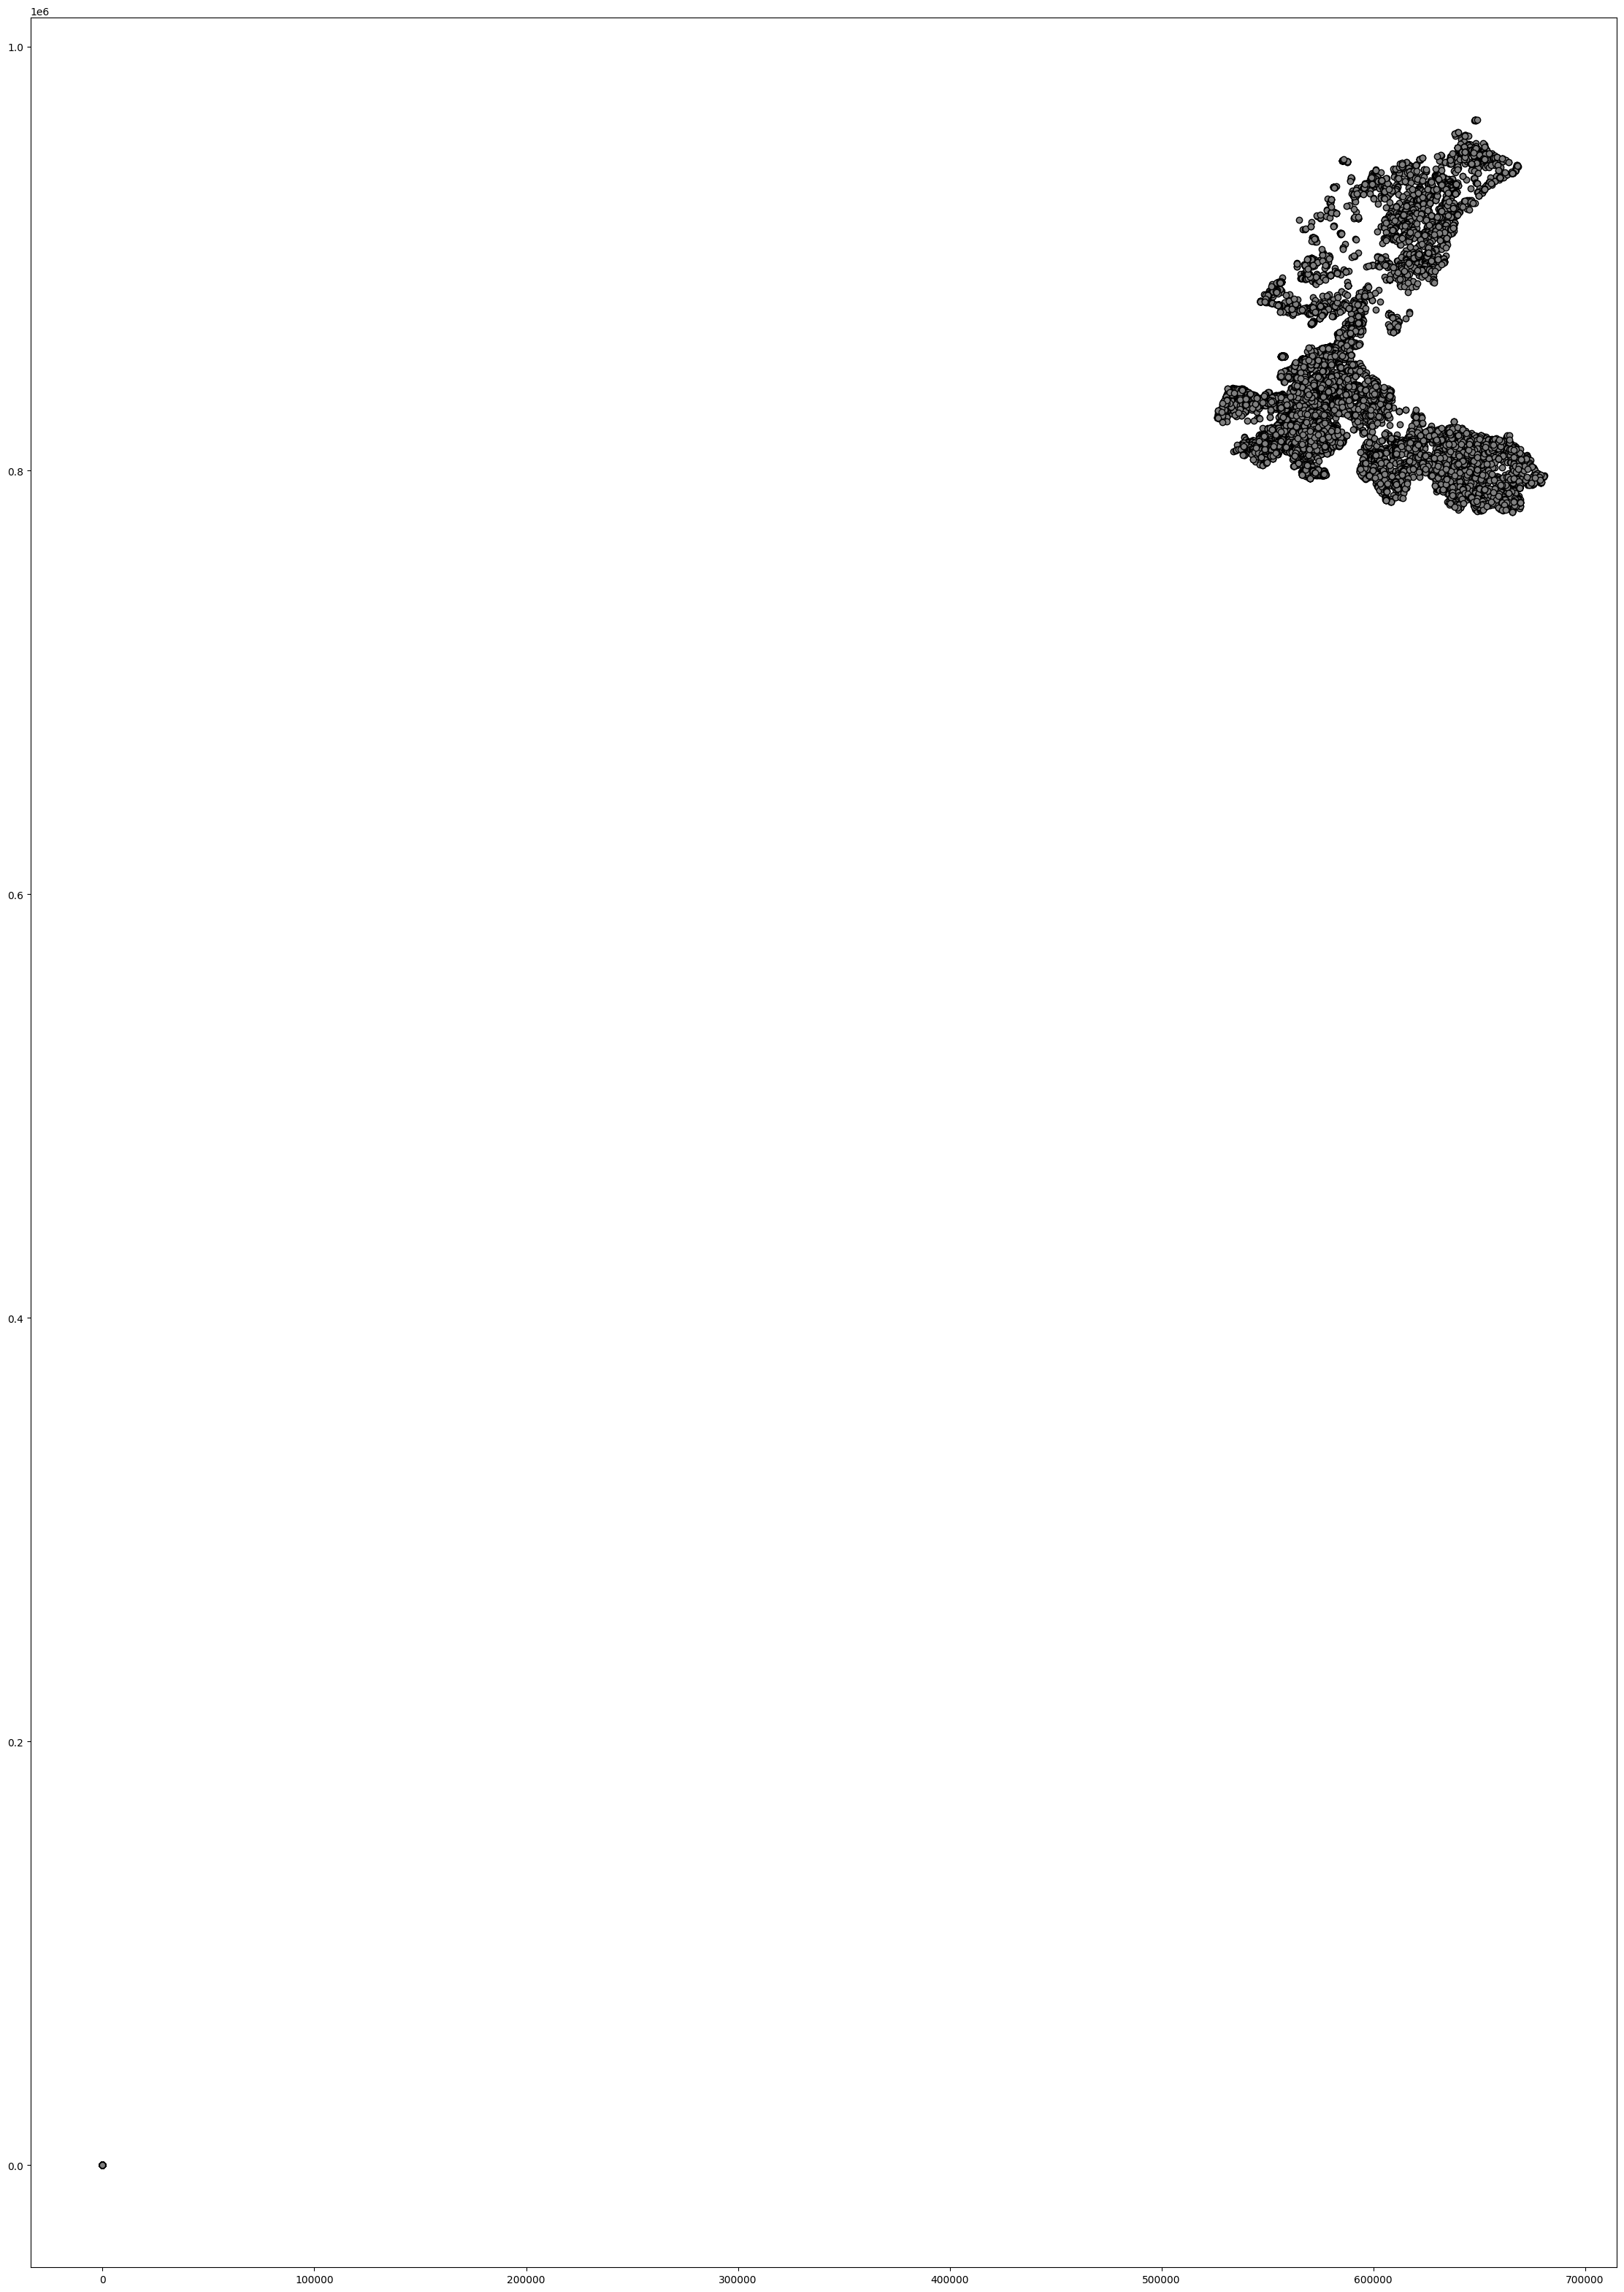

In [19]:
ax, fig = plt.subplots(figsize=(40,40))
filtered_points.plot(ax=fig, color='gray', edgecolor='black')
plt.show()

The above monuments plots shows there are a few outliers. These are the monuments whose geometry is at 0,0. These will be removed, but not discarded, as they may be useful later. They represent objects thought to exist but whose location is not known. They are not included in the analysis. But these would be good targets for inference at a later date. 

In [55]:
print(tii_data.__class__)

<class 'geopandas.geodataframe.GeoDataFrame'>


In [56]:
sligo_donegal.describe()

,CENTROID_X,CENTROID_Y,AREA,OBJECTID,Shape__Are,Shape__Len
count,19.000000,19.000000,1.900000e+01,19.000000,1.900000e+01,19.000000
mean,592908.439474,857128.511053,4.359757e+08,180.789474,4.359667e+08,182085.715783
std,28638.870260,49461.560753,2.546374e+08,77.021338,2.546194e+08,120937.078816
min,543655.490000,797141.300000,1.180191e+08,13.000000,1.180437e+08,63882.383112
25%,571614.380000,815321.210000,2.853697e+08,142.500000,2.854058e+08,119104.213233
50%,592206.800000,843977.630000,3.482685e+08,176.000000,3.482411e+08,136320.485437
75%,611156.970000,901513.415000,5.106198e+08,240.000000,5.106193e+08,209802.923820
max,648936.310000,948447.830000,1.262017e+09,280.000000,1.261950e+09,565575.016132


In [20]:
filtered_points.describe()

,OID_,OBJECTID,COUNTY_ID,ITM_E,ITM_N,LATITUDE,LONGITUDE
count,16328.000000,16328.000000,16328.000000,16328.000000,16328.000000,16328.000000,16328.000000
mean,84998.375735,84998.375735,15.905377,550364.169035,782660.693471,53.773272,-8.664015
std,42458.273907,42458.273907,9.038517,154609.279197,218483.867080,2.031213,2.028502
min,247.000000,247.000000,3.000000,0.000000,0.000000,46.488181,-15.817314
25%,36295.000000,36295.000000,7.000000,561660.000000,808689.750000,54.026150,-8.588038
50%,82076.500000,82076.500000,16.000000,577747.500000,827738.000000,54.197544,-8.341327
75%,121819.250000,121819.250000,25.000000,614681.750000,850289.750000,54.400104,-7.772593
max,162523.000000,162523.000000,25.000000,680954.000000,965456.000000,55.433548,-6.767557


Find the numbers of each type of monument in the dataset. Remove the redundant records which are the second most common entry at 1226. Ringfort- Rath is the most common entry at 3974.



In [22]:
value_counts = filtered_points['MONUMENT_T'].value_counts()
print(value_counts)

MONUMENT_T
Ringfort - rath                                     3974
Redundant record                                    1226
Enclosure                                           1162
Ringfort - cashel                                    813
Souterrain                                           679
                                                    ... 
Kiln - kelp drying                                     1
College                                                1
Religious house - Augustinian, of Arrouaise nuns       1
Henge                                                  1
Pit circle                                             1
Name: count, Length: 276, dtype: int64


In [24]:
filtered_points = filtered_points[filtered_points['MONUMENT_T'] != 'Redundant Record']
filtered_points = filtered_points[filtered_points['MONUMENT_T'] != 'Walled Garden']
filtered_points = filtered_points[filtered_points['MONUMENT_T'] != 'Designed Landscape']
filtered_points = filtered_points[filtered_points['MONUMENT_T'] != 'Garden Ornament']
filtered_points = filtered_points[filtered_points['MONUMENT_T'] != 'Icehouse']
filtered_points = filtered_points[filtered_points['MONUMENT_T'] != 'Lodge']
filtered_points = filtered_points[filtered_points['MONUMENT_T'] != 'Gate Lodge']
filtered_points = filtered_points[filtered_points['MONUMENT_T'] != 'Gate']
filtered_points = filtered_points[filtered_points['MONUMENT_T'] != 'House - 16th/17th century']
filtered_points = filtered_points[filtered_points['MONUMENT_T'] != 'House - 18th/19th century']

# REMOVING THE MONUMENT TYPES WITH ONLY ONE ENTRY

values_to_keep = value_counts[value_counts > 1].index
filtered_points = filtered_points[filtered_points['MONUMENT_T'].isin(values_to_keep)]

# REMOVING THE MONUMENT TYPES THAT ARE NOT RELEVANT TO THE STUDY

values_to_exclude = ['Sheepfold', 'Weir - regulating', 'Wall monument', 'Cave', 'Hospital', 'Font', 'Altar', 'Bastioned fort', 'Signal tower', 'House - 17th century', 'Field Boundary', 'Quarry', 'Religious house - Franciscan Third Order Regular', 'Designed landscaoe feature', 'Headstone', 'Town defences']
                     
# Loop through the list and drop rows
for value in values_to_exclude:
    filtered_points = filtered_points[filtered_points['MONUMENT_T'] != value]      



In [25]:
value_counts = filtered_points['MONUMENT_T'].value_counts()
print(value_counts)

MONUMENT_T
Ringfort - rath                       3974
Redundant record                      1226
Enclosure                             1162
Ringfort - cashel                      813
Souterrain                             679
                                      ... 
Prison                                   2
Deer park                                2
Dovecote                                 2
Inscribed stone (present location)       2
Structure - peatland                     2
Name: count, Length: 207, dtype: int64


In [26]:
unique_values = filtered_points['MONUMENT_T'].unique()
print(unique_values)


['Castle - unclassified' 'Cairn - boundary cairn' 'Redundant record'
 'Graveslab' 'Cross-slab' 'Structure' 'Bawn' 'Ringfort - rath'
 'Font (present location)' 'Stone head' "Children's burial ground"
 'Church' 'Cairn - unclassified' 'Enclosure' 'Standing stone' 'Graveyard'
 'Megalithic structure' 'Crannog' 'Souterrain'
 'Megalithic tomb - portal tomb' 'Ritual site - holy well' 'Bullaun stone'
 'Ringfort - cashel' 'Cross' 'Fulacht fia' 'Ringfort - unclassified'
 'Burial ground' 'Well' 'Kiln - corn-drying' 'Barrow - unclassified'
 'Mill - unclassified' 'Megalithic tomb - unclassified'
 'Designed landscape - tree-ring' 'Kiln' 'Mass-rock' 'Ring-ditch'
 'Stone row' 'Megalithic tomb - court tomb'
 'Castle - Anglo-Norman masonry castle' 'Sweathouse' 'Field system' 'Cist'
 'Water mill - unclassified' 'Mound' 'Building'
 'Megalithic tomb - wedge tomb' 'Boundary mound' 'Hut site' 'Burial'
 'Historic town' 'Ford' 'Bridge' 'Prison' 'Castle - motte and bailey'
 'House - fortified house' 'Castle - to

In [27]:
values_to_exclude = ['Crucifixion plaque', 'Platform', 'Excavation - miscellaneous', 
 'Structure - peatland','Architectural feature','Anomalous stone group' 'House - indeterminate date','Prehistoric site - lithic scatter', 'Mausoleum','Gatehouse','House - fortified house', 'Cathedral', 'Historic town' 'Water mill - unclassified','House - medieval', 'Quay','Religious house - Carmelite friars', 'Inauguration stone','Dovecote', 'Mill - corn','Stone trough','Designed landscape - avenue', 'Excavation - miscellaneous','Weir - fish', 'Designed landscape - tree-ring','Road - road/trackway', 'Building','Mausoleum','Gateway','House - 17th/18th century', 'Field boundary', 'Designed landscape - folly', 'Cultivation ridges','Furnace','Redundant record','Graveslab' 'Cross-slab'
 'Structure', 'Penal Mass station', 'Architectural fragment','Graveyard''Graveslab (present location)','Designed landscape feature', 'Mine', 'Armorial plaque','Country house','Deer park', 'Moated site','Metalworking site',
 'Salt works', 'Kiln - lime', 'Booley hut','Memorial stone', 'Sheela-na-gig','House - early medieval', 'Kiln', 'Kiln - corn-drying','Sweathouse','Road - unclassified togher', 'Chapel', 'Shrine', 'Bridge','Religious house - unclassified','Milling complex','Religious house - Cistercian monks', 'Font (present location)', 'Hearth','Mill - unclassified','Religious house - Augustinian friars', 'Slab-lined burial','Water mill - unclassified', 'Habitation site','Hermitage' 'Religious house - Franciscan friars','Settlement deserted - medieval','Field system','Enclosure', 'Cist', 'Burial ground','Penitential station', 'Religious house - Dominican friars','Inn']
                     
# Loop through the list and drop rows
for value in values_to_exclude:
    filtered_points = filtered_points[filtered_points['MONUMENT_T'] != value]    

In [28]:
unique_values = filtered_points['MONUMENT_T'].unique()
print(unique_values)

['Castle - unclassified' 'Cairn - boundary cairn' 'Graveslab' 'Cross-slab'
 'Structure' 'Bawn' 'Ringfort - rath' 'Stone head'
 "Children's burial ground" 'Church' 'Cairn - unclassified'
 'Standing stone' 'Graveyard' 'Megalithic structure' 'Crannog'
 'Souterrain' 'Megalithic tomb - portal tomb' 'Ritual site - holy well'
 'Bullaun stone' 'Ringfort - cashel' 'Cross' 'Fulacht fia'
 'Ringfort - unclassified' 'Well' 'Barrow - unclassified'
 'Megalithic tomb - unclassified' 'Mass-rock' 'Ring-ditch' 'Stone row'
 'Megalithic tomb - court tomb' 'Castle - Anglo-Norman masonry castle'
 'Mound' 'Megalithic tomb - wedge tomb' 'Boundary mound' 'Hut site'
 'Burial' 'Historic town' 'Ford' 'Prison' 'Castle - motte and bailey'
 'Castle - tower house' 'Hilltop enclosure' 'Stone circle'
 'Bullaun stone (present location)' 'Promontory fort - inland'
 'Megalithic tomb - passage tomb' 'Round tower'
 'Religious house - Augustinian canons' 'Ecclesiastical enclosure'
 'Ecclesiastical residence' 'Cross-inscribed 

In [13]:
value_counts = filtered_points['MONUMENT_T'].value_counts()
print(value_counts)

MONUMENT_T
Ringfort - rath                     3974
Ringfort - cashel                    813
Souterrain                           679
Crannog                              460
Standing stone                       453
                                    ... 
Rock scribing - folk art               2
Stone circle - embanked                2
Cairn - wayside cairn                  2
Monumental structure                   2
Sheela-na-gig (present location)       2
Name: count, Length: 139, dtype: int64


In [14]:
filtered_points.info()


<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 12298 entries, 247 to 162382
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OID_        12298 non-null  int64   
 1   OBJECTID    12298 non-null  int64   
 2   ENTITY_ID   12298 non-null  object  
 3   CLASS_CODE  12298 non-null  object  
 4   SMRS        12298 non-null  object  
 5   COUNTY      12298 non-null  object  
 6   TOWNLAND    12298 non-null  object  
 7   COUNTY_ID   12298 non-null  int64   
 8   ZONE_ID     11460 non-null  object  
 9   ITM_E       12298 non-null  int64   
 10  ITM_N       12298 non-null  int64   
 11  LATITUDE    12298 non-null  float64 
 12  LONGITUDE   12298 non-null  float64 
 13  MONUMENT_T  12298 non-null  object  
 14  FIRST_EDIT  4456 non-null   object  
 15  LATEST_EDI  9866 non-null   object  
 16  WEBSITE_LI  12298 non-null  object  
 17  WEB_NOTES   12298 non-null  object  
 18  geometry    12298 non-null  geometry
dty

In [29]:
filtered_points_2 = filtered_points.copy()
filtered_points_2.to_file('/Users/mensab/Documents/GitHub/Artefact/Colab/filtered_points_2.shp')

In [30]:
filtered_points_2 = gpd.read_file('/Users/mensab/Documents/GitHub/Artefact/Colab/filtered_points_2.shp')    
filtered_points_2.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 12296 entries, 0 to 12295
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OID_        12296 non-null  int64   
 1   OBJECTID    12296 non-null  int64   
 2   ENTITY_ID   12296 non-null  object  
 3   CLASS_CODE  12296 non-null  object  
 4   SMRS        12296 non-null  object  
 5   COUNTY      12296 non-null  object  
 6   TOWNLAND    12296 non-null  object  
 7   COUNTY_ID   12296 non-null  int64   
 8   ZONE_ID     11460 non-null  object  
 9   ITM_E       12296 non-null  int64   
 10  ITM_N       12296 non-null  int64   
 11  LATITUDE    12296 non-null  float64 
 12  LONGITUDE   12296 non-null  float64 
 13  MONUMENT_T  12296 non-null  object  
 14  FIRST_EDIT  4456 non-null   object  
 15  LATEST_EDI  9866 non-null   object  
 16  WEBSITE_LI  12296 non-null  object  
 17  WEB_NOTES   12296 non-null  object  
 18  geometry    12296 non-null  geometry
d

In [31]:
unique_values = filtered_points_2['MONUMENT_T'].unique()
print(unique_values)
print (len(unique_values))

['Castle - unclassified' 'Cairn - boundary cairn' 'Graveslab' 'Cross-slab'
 'Structure' 'Bawn' 'Ringfort - rath' 'Stone head'
 "Children's burial ground" 'Church' 'Cairn - unclassified'
 'Standing stone' 'Graveyard' 'Megalithic structure' 'Crannog'
 'Souterrain' 'Megalithic tomb - portal tomb' 'Ritual site - holy well'
 'Bullaun stone' 'Ringfort - cashel' 'Cross' 'Fulacht fia'
 'Ringfort - unclassified' 'Well' 'Barrow - unclassified'
 'Megalithic tomb - unclassified' 'Mass-rock' 'Ring-ditch' 'Stone row'
 'Megalithic tomb - court tomb' 'Castle - Anglo-Norman masonry castle'
 'Mound' 'Megalithic tomb - wedge tomb' 'Boundary mound' 'Hut site'
 'Burial' 'Historic town' 'Ford' 'Prison' 'Castle - motte and bailey'
 'Castle - tower house' 'Hilltop enclosure' 'Stone circle'
 'Bullaun stone (present location)' 'Promontory fort - inland'
 'Megalithic tomb - passage tomb' 'Round tower'
 'Religious house - Augustinian canons' 'Ecclesiastical enclosure'
 'Ecclesiastical residence' 'Cross-inscribed 

In [32]:
exclude_these = ['Settlement platform', 'Causeway','Ecclesiastical site', 'Hermitage', 'Religious house - Franciscan friars', 'Midden','Pit','Religious house - Augustinian canons','Stone sculpture','Graveslab (present location)','Post row - peatland','Inscribed slab', 'Seaweed stand','Inscribed slab', 'Seaweed stand','Tomb - unclassified','Anomalous stone group', 'House - indeterminate date','Clochan','Fulacht fia','Water mill - horizontal-wheeled','Graveyard','Nonumental structure','Ritual site - holy tree/bush','Burnt mound','Stone sculpture (present location)','Burnt spread','Mass-rock','Urn burial','Bullaun stone (present location)','Stone head',"Children's burial ground",'Well','Cupmarked stone','Earthwork','Burial','Cursing stone','Flat cemetery','Rock art', 'Castle - motte and bailey','Castle - Anglo-Norman masonry castle', 'Historic town', 'Fortification', 'Structure','Graveslab','Cross-slab','Kerb circle','Boulder burial', 'Inscribed stone (present location)','Rock art (present location)']

for value in exclude_these:
    filtered_points_2 = filtered_points_2[filtered_points_2['MONUMENT_T'] != value]    

In [33]:
value_counts = filtered_points_2['MONUMENT_T'].value_counts()
print(value_counts)

MONUMENT_T
Ringfort - rath                     3974
Ringfort - cashel                    813
Souterrain                           679
Crannog                              460
Standing stone                       453
                                    ... 
Tomb - effigial                        2
Cross - Tau cross                      2
Windmill                               2
Burnt pit                              2
Sheela-na-gig (present location)       2
Name: count, Length: 92, dtype: int64


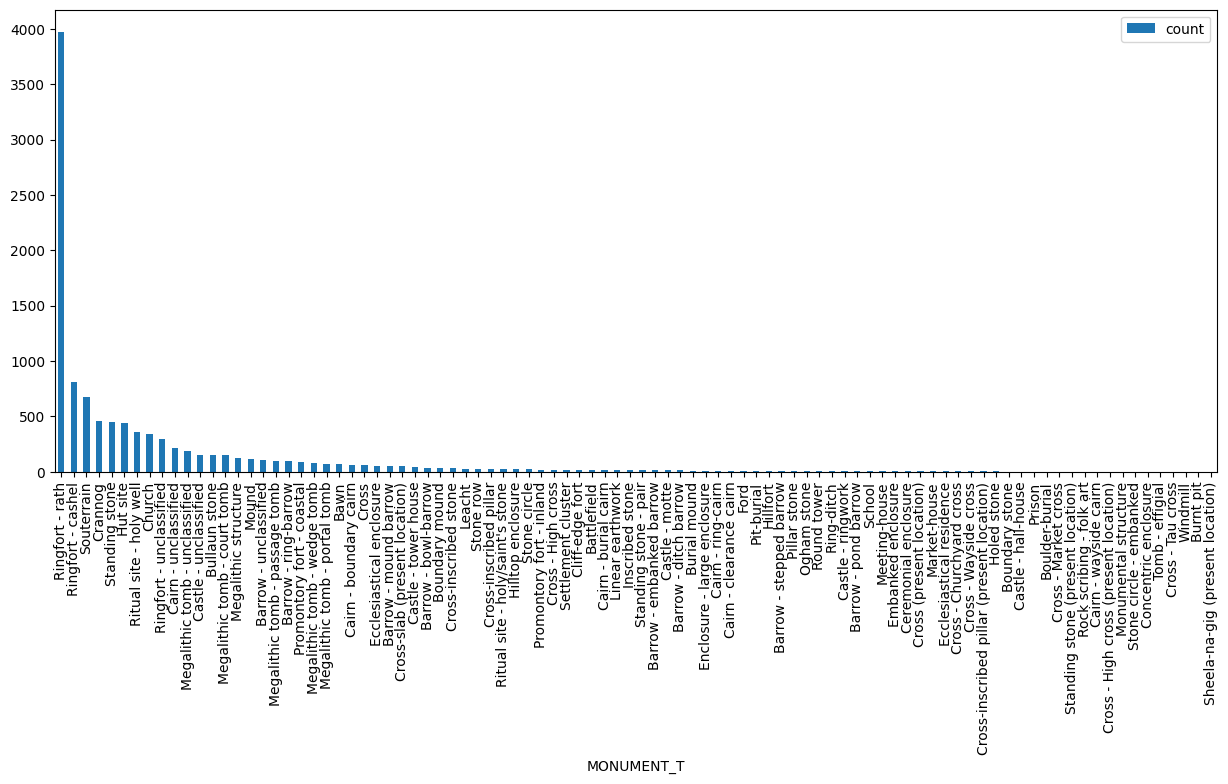

In [34]:
pd.DataFrame(filtered_points_2['MONUMENT_T'].value_counts()).plot.bar(width=0.5, figsize=(15,6))
plt.show()




In [35]:
unique_values = filtered_points_2['MONUMENT_T'].unique()
print(unique_values)
print (len(unique_values))

['Castle - unclassified' 'Cairn - boundary cairn' 'Bawn' 'Ringfort - rath'
 'Church' 'Cairn - unclassified' 'Standing stone' 'Megalithic structure'
 'Crannog' 'Souterrain' 'Megalithic tomb - portal tomb'
 'Ritual site - holy well' 'Bullaun stone' 'Ringfort - cashel' 'Cross'
 'Ringfort - unclassified' 'Barrow - unclassified'
 'Megalithic tomb - unclassified' 'Ring-ditch' 'Stone row'
 'Megalithic tomb - court tomb' 'Mound' 'Megalithic tomb - wedge tomb'
 'Boundary mound' 'Hut site' 'Ford' 'Prison' 'Castle - tower house'
 'Hilltop enclosure' 'Stone circle' 'Promontory fort - inland'
 'Megalithic tomb - passage tomb' 'Round tower' 'Ecclesiastical enclosure'
 'Ecclesiastical residence' 'Cross-inscribed stone' 'Ceremonial enclosure'
 'Enclosure - large enclosure' 'Cross - Market cross' 'School'
 'Market-house' 'Inscribed stone' 'Concentric enclosure'
 'Settlement cluster' 'Linear earthwork'
 "Ritual site - holy/saint's stone" 'Ogham stone' 'Cross - Wayside cross'
 'Promontory fort - coastal'

In [36]:
exclude_these = ['Sheela-na-gig (present location)','Monumental structure','School','Prison','Bullaun stone','Rock scribing - folk art','Windmill','Tomb - effigial','Market-house','Hut site']

for value in exclude_these:
    filtered_points_2 = filtered_points_2[filtered_points_2['MONUMENT_T'] != value]

In [37]:
# pd.DataFrame (filtered_points_2['MONUMENT_T'].nunique()).plot.bar()

# Save unique values of filtered_points and their counts to a text file

with open('filtered_values_count.txt', 'w') as file:
    for value, count in value_counts.items():
        file.write(f"{value}: {count}\n")

In [38]:
# Save as a shapefile.

filtered_points_2.to_file('/Users/mensab/Documents/GitHub/Artefact/Colab/filtered_points_2.shp')



In [74]:
import IPython.display as display

display.YouTubeVideo('z09ZCayL4Uk?si=5H62h85AxBcw5raU')


Load soils and rivers data and see if they are usable for the project

In [75]:
soils_map = gpd.read_file("/Users/mensab/Documents/GISMapFiles/SOIL_SISNationalSoils_shp/Data/SOIL_SISNationalSoils_Shp")
soils_map

KeyboardInterrupt: 

In [ ]:
soils_map.columns


Index(['OBJECTID', 'Associatio', 'Associat_1', 'Associat_2', 'Texture_Su',
       'ha', 'URL', 'UniqueID', 'DRAINAGE', 'TEXTURE', 'DEPTH', 'SHAPE_Leng',
       'SHAPE_Area', 'SOC', 'geometry'],
      dtype='object')

In [ ]:
rivers_lakes = gpd.read_file("/Users/mensab/Documents/GISMapFiles/Rivers&Lakes/Shapefiles")
rivers_lakes


,OBJECTID,SEG_CD,NAME,AREA_,HECTARE,PERIMETER,HYDRO_AR,ORDER_,OS_LAYER,SOURCE,LWB,EDENLakeCo,Shape_STAr,Shape_STLe,geometry
0,1,34_1,NaN,0.002,0.174650,148.152773,34,-99.0,reservoir,epa,N,NaN,1.746498e+03,148.152773,"POLYGON ((113947.176 292650.532, 113947.176 29..."
1,2,34_2,NaN,0.002,0.168753,145.631645,34,-99.0,reservoir,epa,N,NaN,1.687534e+03,145.631645,"POLYGON ((113891.838 292649.223, 113891.838 29..."
2,3,34_3,NaN,0.000,0.045238,75.408867,34,-99.0,reservoir,epa,N,NaN,4.523752e+02,75.408867,"POLYGON ((119811.159 319583.855, 119811.151 31..."
3,4,34_4,NaN,0.001,0.060457,102.438843,34,-99.0,pond,epa,N,NaN,6.045697e+02,102.438843,"POLYGON ((148454.106 281486.625, 148454.362 28..."
4,5,34_5,NaN,0.003,0.259570,206.013992,34,-99.0,pond,epa,N,NaN,2.595699e+03,206.013992,"POLYGON ((141211.791 283056.662, 141213.903 28..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12212,9192,32_509a,Pollacappul Lough,0.254,25.509374,3827.503729,32,5.0,NaN,epa,Y,32001330040,2.550937e+05,3827.503729,"POLYGON ((75473.267 258248.239, 75485.251 2582..."
12213,9193,32_509b,Kylemore Lough,1.335,134.091553,6016.860382,32,5.0,NaN,epa,Y,32001330050,1.340916e+06,6016.860382,"POLYGON ((76100.587 258107.143, 76090.524 2581..."
12214,9194,26_747c,Tap (Lough),0.112,11.254331,2149.103677,26,6.0,LAKE,epa,Y,260155a1815,1.125433e+05,2149.103677,"POLYGON ((200673.808 294130.860, 200881.064 29..."
12215,937,32_402,Beaghcauneen Lough,0.184,18.520070,3378.220801,32,3.0,NaN,epa,Y,32t4_320270,1.852007e+05,3378.220801,"POLYGON ((68219.412 246975.360, 68208.640 2469..."


In [ ]:
rivers_lakes.columns


Index(['OBJECTID', 'SEG_CD', 'NAME', 'AREA_', 'HECTARE', 'PERIMETER',
       'HYDRO_AR', 'ORDER_', 'OS_LAYER', 'SOURCE', 'LWB', 'EDENLakeCo',
       'Shape_STAr', 'Shape_STLe', 'geometry'],
      dtype='object')

In [ ]:
ground_cover = gpd.read_file("/Users/mensab/Documents/GISMapFiles/CLC18_IE_ITM")
ground_cover

,OBJECTID,ID,CODE_18,Class_Desc,Area_Ha,Shape_Leng,Shape_Area,geometry
0,1,IE_1,111,Continuous urban fabric,3.593744e+01,3.399197e+03,3.593744e+05,"POLYGON ((549066.345 555256.482, 549072.885 55..."
1,2,IE_2,111,Continuous urban fabric,1.785159e+02,9.113998e+03,1.785159e+06,"POLYGON ((567744.494 572317.427, 567759.908 57..."
2,3,IE_3,111,Continuous urban fabric,2.767229e+01,3.184751e+03,2.767229e+05,"POLYGON ((610935.924 577294.210, 610929.055 57..."
3,4,IE_4,111,Continuous urban fabric,4.389431e+01,3.740162e+03,4.389431e+05,"POLYGON ((496745.856 591197.539, 496727.529 59..."
4,5,IE_5,111,Continuous urban fabric,5.020679e+01,3.334811e+03,5.020679e+05,"POLYGON ((555696.702 598906.682, 555702.434 59..."
...,...,...,...,...,...,...,...,...
18877,18878,IE_18878,522,Estuaries,5.021254e+01,5.985962e+03,5.021254e+05,"POLYGON ((579946.993 927185.232, 580019.644 92..."
18878,18879,IE_18879,522,Estuaries,1.747832e+02,1.642710e+04,1.747832e+06,"POLYGON ((609130.779 934002.585, 609135.398 93..."
18879,18880,IE_18880,522,Estuaries,8.743091e+01,9.342406e+03,8.743091e+05,"POLYGON ((592100.667 934008.175, 592102.878 93..."
18880,18881,IE_18881,522,Estuaries,2.865799e+02,1.934526e+04,2.865799e+06,"POLYGON ((642774.180 951771.885, 642777.826 95..."


In [ ]:
ground_cover.columns


Index(['OBJECTID', 'ID', 'CODE_18', 'Class_Desc', 'Area_Ha', 'Shape_Leng',
       'Shape_Area', 'geometry'],
      dtype='object')

In [ ]:
unique_ground_cover = ground_cover['Class_Desc'].unique()
print(unique_ground_cover)

['Continuous urban fabric' 'Discontinuous urban fabric'
 'Industrial or commercial units'
 'Road and rail networks and associated land' 'Port areas' 'Airports'
 'Mineral extraction sites' 'Dump sites' 'Construction sites'
 'Green urban areas' 'Sport and leisure facilities'
 'Non-irrigated arable land' 'Fruit trees and berry plantations'
 'Pastures' 'Complex cultivation patterns'
 'Land principally occupied by agriculture, with significant areas of natural vegetation'
 'Broad-leaved forest' 'Coniferous forest' 'Mixed forest'
 'Natural grasslands' 'Moors and heathland' 'Transitional woodland-shrub'
 'Beaches, dunes, sands' 'Bare rocks' 'Sparsely vegetated areas'
 'Burnt areas' 'Inland marshes' 'Peat bogs' 'Salt marshes'
 'Intertidal flats' 'Water courses' 'Water bodies' 'Coastal lagoons'
 'Estuaries' 'Sea and ocean']


In [83]:
import rasterio as rio

# File paths for GeoTIFF, HDR, and TFW files
geotiff_path = '/Users/mensab/Documents/GISMapFiles/srtm_35_02/srtm_35_02.tif'
hdr_path = '/Users/mensab/Documents/GISMapFiles/srtm_35_02/srtm_35_02.hdr'
tfw_path = '/Users/mensab/Documents/GISMapFiles/srtm_35_02/srtm_35_02.tfw'

# Open GeoTIFF file with context manager
with rio.Env():
    with rio.open(geotiff_path) as src:
        # Read data and metadata
        data = src.read()
        metadata = src.meta

        # Print metadata to understand the geospatial information
        print(metadata)






{'driver': 'GTiff', 'dtype': 'int16', 'nodata': -32768.0, 'width': 6000, 'height': 6000, 'count': 1, 'crs': CRS.from_epsg(4326), 'transform': Affine(0.0008333333333333334, 0.0, -10.0,
       0.0, -0.0008333333333333334, 55.0)}


In [84]:
print(data.shape)

(1, 6000, 6000)


In [88]:
nasa_map = rxr.open_rasterio(geotiff_path)

In [91]:
w_nasa_map = weights.contiguity.Queen.from_xarray(nasa_map)
w_nasa_map


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd

hgt_file = "/Users/mensab/Documents/GISMapFiles/Heightmaps/N41W008.hgt"

# Determine the size of the data
data_size = np.fromfile(hgt_file, np.dtype('>i2')).size

# Calculate the side length of the square (assuming a square grid)
side_length = int(data_size ** 0.5)

## Read the binary data and reshape it
hgt_data = np.fromfile(hgt_file, np.dtype('>i2')).reshape(side_length, side_length)

# Create a GeoDataFrame with the elevation data
# Assume a fixed grid size (adjust as needed)
grid_size = 1.0  # 1-degree grid spacing
lats = np.linspace(0, side_length * grid_size, side_length, endpoint=False)
lons = np.linspace(0, side_length * grid_size, side_length, endpoint=False)

elevation_gdf = gpd.GeoDataFrame(
    {'Elevation': hgt_data.flatten()},
    geometry=gpd.points_from_xy(lons, lats),
    crs='EPSG:4326'  # Assuming WGS 84 coordinate system
)

# Visualize the elevation data on a map
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

fig, ax = plt.subplots(figsize=(12, 8))
world.boundary.plot(ax=ax, linewidth=1, color="k")
elevation_gdf.plot(column='Elevation', cmap='terrain', ax=ax, legend=True)
plt.title('Elevation Data Visualization')
plt.show()




# Plot the data using Matplotlib's imshow()
# Visualize the elevation data
#plt.figure(figsize=(8, 8))
#plt.imshow(hgt_data, cmap='terrain', extent=(0, 1, 0, 1))
#plt.colorbar(label='Elevation (meters)')
#plt.title('Elevation Map')
#plt.show()


ValueError: Length of values (3601) does not match length of index (12967201)

In [ ]:
# Create a map centered at a specific location
m = folium.Map(location=[53.349805, -6.26031], crs:"EPSG2157", zoom_start=10)

# Add a marker for every record in the filtered_points GeoDataFrame 
for i, row in filtered_points.iterrows():
    # Get the lat and lon of the current record
    lon = row.geometry.x
    lat = row.geometry.y
    
    # Create a marker at the location
    marker = folium.Marker([lat, lon])
    
    # Add the marker to the map
    marker.add_to(m)

# Display the map
# m.save('map.html')
m




SyntaxError: positional argument follows keyword argument (1627397997.py, line 2)